In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import sys
import astropy as ast
import matplotlib.pyplot as plt
import pandas as pd
import glob
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import matplotlib.path as mpath
from pathlib import Path
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FormatStrFormatter, FuncFormatter
from io import StringIO
import re
fourpointstar = mpath.Path.unit_regular_star(4)
sevenpointstar = mpath.Path.unit_regular_star(7)
eightpointstar = mpath.Path.unit_regular_star(8)
from metrics import fit_plotter_flux, compute_lomb_scargle, plot_periodogram, info, plot_phase_fold_binned, plot_phase_fold, offset_corrector

In [2]:
stats = pd.read_csv('./summary_results08182026.csv')
df_smc = stats[stats['RA'] < 40]
df_lmc = stats[stats['RA'] > 40]
coords = pd.read_csv('./merged_smc_lmc_coords_all.csv', comment='#', sep="\\s+", names=['RA', 'DEC'])
hrd_zoning = pd.read_csv('./HR_and_case-by-case/HRD_zoning_priority_03222026.csv')

hrd_priority = pd.read_csv("./HR_and_case-by-case/HRD_zoning_priority_03202026.csv")
magellan_spectroscopy_orig = pd.read_csv("./magellan_spectroscopy/magellan_spectroscopy_to_original_matches.csv")
magellan_spectroscopy_prefinal = pd.read_csv("./magellan_spectroscopy/magellan_spectroscopy_to_prefinal_matches.csv")
plt.rcParams['font.family'] = 'serif'

In [3]:
# Read VizieR VOTable files with embedded CSV payloads.

def read_vizier_votable_csv(path):
    with open(path, 'r', encoding='utf-8') as f:
        text = f.read()
    match = re.search(r'<!\[CDATA\[(.*?)\]\]>', text, flags=re.S)
    if match is None:
        raise ValueError(f'No CDATA CSV block found in {path}')
    csv_block = match.group(1).strip()
    df = pd.read_csv(StringIO(csv_block), sep=';', skiprows=[1, 2], engine='python')
    if len(df) == 0:
        raise ValueError(f'Parsed zero rows from {path}')
    return df

rsg_smc = read_vizier_votable_csv('./HR_and_case-by-case/RSG_SMC_massey23.tsv')
rsg_lmc = read_vizier_votable_csv('./HR_and_case-by-case/RSG_LMC_massey23.tsv')

# Ensure numeric columns for plotting.
for _df in (rsg_smc, rsg_lmc):
    _df['Temp'] = pd.to_numeric(_df['Temp'], errors='coerce')
    _df['LogLum'] = pd.to_numeric(_df['LogLum'], errors='coerce')

def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = mpl.colors.LinearSegmentedColormap.from_list(
        f'trunc({cmap.name},{minval:.2f},{maxval:.2f})',
        cmap(np.linspace(minval, maxval, n))
    )
    return new_cmap

In [4]:
# loading in evolutionary models
eep_directory_lmc = '../MIST_models_LMC_v2.5/'
evol_files_lmc = glob.glob(f'{eep_directory_lmc}*.track.*')
# order files by mass 
evol_files_lmc = sorted(evol_files_lmc, key=lambda x: float(x.split('/')[-1].split('M')[0]))
print(evol_files_lmc)

# loading in evolutionary models
eep_directory_smc = '../MIST_models_SMC_v2.5/'
evol_files_smc = glob.glob(f'{eep_directory_smc}*.track.*')
# order files by mass 
evol_files_smc = sorted(evol_files_smc, key=lambda x: float(x.split('/')[-1].split('M')[0]))
print(evol_files_smc)

def Open_File(file_name):
    # Get the column names
    row = open(file_name, 'r').readlines()
    # It's the last comment in the file so get all the comments
    comments = [x for x in row if '#' in x  ]
    # Split the last row into individual keys, exclude the '#'
    columns = comments[-1].split()[1:]
    # Strip any blank spaces
    columns = [x.strip(' ') for x in columns]
    # Read in as pandas dataframe
    df = pd.read_csv(file_name, comment='#',names = columns,delimiter='\\s+')
    return df

df = Open_File(evol_files_lmc[0])

# Show the first few rows to check that everything looks okay
df.head()

['../MIST_models_LMC_v2.5/0080000M.track.eep', '../MIST_models_LMC_v2.5/0100000M.track.eep', '../MIST_models_LMC_v2.5/0120000M.track.eep', '../MIST_models_LMC_v2.5/0140000M.track.eep', '../MIST_models_LMC_v2.5/0160000M.track.eep', '../MIST_models_LMC_v2.5/0180000M.track.eep', '../MIST_models_LMC_v2.5/0200000M.track.eep', '../MIST_models_LMC_v2.5/0220000M.track.eep', '../MIST_models_LMC_v2.5/0240000M.track.eep', '../MIST_models_LMC_v2.5/0260000M.track.eep', '../MIST_models_LMC_v2.5/0280000M.track.eep', '../MIST_models_LMC_v2.5/0300000M.track.eep']
['../MIST_models_SMC_v2.5/0080000M.track.eep', '../MIST_models_SMC_v2.5/0100000M.track.eep', '../MIST_models_SMC_v2.5/0120000M.track.eep', '../MIST_models_SMC_v2.5/0140000M.track.eep', '../MIST_models_SMC_v2.5/0160000M.track.eep', '../MIST_models_SMC_v2.5/0180000M.track.eep', '../MIST_models_SMC_v2.5/0200000M.track.eep', '../MIST_models_SMC_v2.5/0220000M.track.eep', '../MIST_models_SMC_v2.5/0240000M.track.eep', '../MIST_models_SMC_v2.5/0260000

,star_age,star_mass,star_mdot,he_core_mass,c_core_mass,o_core_mass,log_L,log_L_div_Ledd,log_LH,log_LHe,...,conv_env_top_mass,conv_env_bot_mass,conv_env_top_radius,conv_env_bot_radius,conv_env_turnover_time_l_t,conv_env_turnover_time_l_b,conv_env_turnover_time_g,envelope_binding_energy,total_moment_of_inertia,phase
0,22989.328961,7.999979,-7.440683e-10,0.0,0.0,0.0,2.965350,-3.221819,2.103756,-99.0,...,7.999978,7.637108,38.622225,27.160606,4.459788e+06,6.136808e+06,1.050548e+07,-3.818563e+48,1.129854e+58,-1.0
1,23460.903756,7.999979,-7.626775e-10,0.0,0.0,0.0,2.971875,-3.207462,2.102898,-99.0,...,7.999978,7.674962,38.816601,27.521753,4.230371e+06,5.848332e+06,9.917021e+06,-3.864605e+48,1.108133e+58,-1.0
2,23934.601106,7.999978,-7.825230e-10,0.0,0.0,0.0,2.978666,-3.200043,2.101941,-99.0,...,7.999978,7.710468,39.019525,27.896899,4.021902e+06,5.560575e+06,9.977531e+06,-3.911698e+48,1.086432e+58,-1.0
3,24410.240181,7.999978,-8.035064e-10,0.0,0.0,0.0,2.985707,-3.192821,2.100911,-99.0,...,7.999977,7.743613,39.228752,28.255671,3.799566e+06,5.285331e+06,1.011637e+07,-3.959877e+48,1.064743e+58,-1.0
4,24887.712864,7.999978,-8.255739e-10,0.0,0.0,0.0,2.992952,-3.185107,2.099819,-99.0,...,7.999977,7.774298,39.442129,28.649330,3.588135e+06,5.010764e+06,9.873879e+06,-4.009193e+48,1.043060e+58,-1.0


In [5]:
def Get_MS(mist_df):
    # Phase = 0 corresponds to the main sequence
    MS = mist_df.loc[mist_df['phase'] == 0.0]
    return MS

def get_RGB(mist_df):
    # Phase = 2 corresponds to the RGB
    RGB = mist_df.loc[mist_df['phase'] == 2.0]
    return RGB

def get_phase(mist_df):
    # Phase = -1 is pre-main sequence
    # Phase = 6 is post-AGB
    # plot everything else 
    RGB = mist_df.loc[(mist_df['phase'] != -1.0) & (mist_df['phase'] != 6.0)]
    return RGB

In [6]:
box1 = [307,286,756, 1189] #1168
# box4 = [1130,1182,911,978, 1101]
box2 = [716,541,579,1100]
box3 = [780,670,765, 378]
proposed = [307,1130,613,1085,716,953,250,890,156,40,780,522]
chosen = [40, 156, 250, 307, 522, 613,  716,   780,  890, 953, 1085, 1130, ]#, 522]
highL_cands = [403,534,585,596,602,720,725,741,744,785,877,889,1020,1028,1029,1037,1055,1058,1087,1095,1102,1117,1120,1131,1166,1187,1195,1201,1203,1211,1212,1213,1252]

In [7]:
def plot_evol_tracks_multiple(files, lmc=True):
    '''
    Create two similar HRD subplots side by side, with separate code blocks
    so each panel can be customized independently later.
    '''
    fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

    cmap = cm.copper
    norm = mcolors.Normalize(vmin=0, vmax=len(files) - 1)

    # -----------------------------
    # Left panel
    # -----------------------------
    for i, file_i in enumerate(files):
        df_i = Open_File(file_i)
        phase_i = get_phase(df_i)
        color = cmap(norm(i))

        ax_left.plot(phase_i['log_Teff'], phase_i['log_L'], "-", color=color, alpha=0.5, zorder=3)

        x_label = 4.071
        idx_near = (phase_i['log_Teff'] - x_label).abs().idxmin()
        y_label = phase_i.loc[idx_near, 'log_L']

        ax_left.annotate(
            str(int(file_i.split('/')[-1].split('.track')[0][1:3])) + r" M$_\odot$",
            xy=(x_label, y_label),
            xytext=(0, 2),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=12,
            color=color,
            zorder=20,
            alpha=0.8,
            annotation_clip=False
        )

    mask_left = stats[
        (stats['logT'] > 3.62)
        & (stats['logT'] < 4.05)
        & (stats['logL'] > 3.95)
        & (stats['logL'] < 5.48)
        & (stats['alarm_level_flag'] == 0)
    ]
    ax_left.vlines(3.62, 3.95, 5.5, color='gray', alpha=0.5, linestyle='--', zorder=20)
    ax_left.scatter(mask_left['logT'], mask_left['logL'], alpha=0.9, color='xkcd:sun yellow', edgecolors='xkcd:copper', label='YSG', zorder=8)
    ax_left.scatter(np.log10(rsg_smc['Temp']), rsg_smc['LogLum'], alpha=0.3, c='tab:red', label='RSG', zorder=6)
    ax_left.scatter(np.log10(rsg_lmc['Temp']), rsg_lmc['LogLum'], alpha=0.3, c='tab:red', zorder=6)

    sn_zorder = 4
    sn_color = "xkcd:cyan"
    ax_left.errorbar(3.825, 5.0, xerr=0.025, yerr=0.05, fmt='o', color=sn_color, label='SN Progenitor', zorder=sn_zorder)
    ax_left.errorbar(3.72, 5.17, xerr=0.08, yerr=0.04, fmt='o', color=sn_color, zorder=sn_zorder)
    ax_left.errorbar(3.98, 5.14, xerr=[[0.16], [0.21]], yerr=[[0.39], [0.22]], fmt='o', color=sn_color, zorder=sn_zorder)
    ax_left.errorbar(3.63, 4.94, xerr=0.01, yerr=0.06, fmt='o', color=sn_color, zorder=sn_zorder)
    ax_left.errorbar(3.78, 4.92, xerr=0.02, yerr=0.2, fmt='o', color=sn_color, zorder=sn_zorder)
    ax_left.errorbar(3.63, 5.1, xerr=0.05, yerr=0.3, fmt='o', color=sn_color, zorder=sn_zorder)

    ax_left.invert_xaxis()
    ax_left.legend(bbox_to_anchor=(1.0, 1), loc='upper left', title_fontsize=16, fontsize=18, markerscale=1.5)
    ax_left.set_xlim(4.1, 3.59)
    ax_left.set_ylim(3.93, 5.48)
    ax_left.tick_params(axis='both', direction='in', labelsize=16)
    ax_left.set_xlabel('log(T/[K])', fontsize=24)
    ax_left.set_ylabel('log(L/[L$_☉$])', fontsize=24)

    # -----------------------------
    # Right panel (currently same as left; edit here independently)
    # -----------------------------
    for i, file_i in enumerate(files):
        df_i = Open_File(file_i)
        phase_i = get_phase(df_i)
        color = cmap(norm(i))

        ax_right.plot(phase_i['log_Teff'], phase_i['log_L'], "-", color=color, alpha=0.5, zorder=3)

        x_label = 4.071
        idx_near = (phase_i['log_Teff'] - x_label).abs().idxmin()
        y_label = phase_i.loc[idx_near, 'log_L']

        ax_right.annotate(
            str(int(file_i.split('/')[-1].split('.track')[0][1:3])) + r" M$_\odot$",
            xy=(x_label, y_label),
            xytext=(0, 2),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=12,
            color=color,
            zorder=20,
            alpha=0.8,
            annotation_clip=False
        )

    mask_right = stats[
        (stats['logT'] > 3.62)
        & (stats['logT'] < 4.05)
        & (stats['logL'] > 3.95)
        & (stats['logL'] < 5.48)
        & (stats['alarm_level_flag'] == 0)
    ]
    ax_right.vlines(3.62, 3.95, 5.5, color='gray', alpha=0.5, linestyle='--', zorder=20)
    ax_right.scatter(mask_right['logT'], mask_right['logL'], alpha=0.9, color='xkcd:orangey yellow', edgecolors='xkcd:copper', label='YSG', zorder=8)
    ax_right.scatter(np.log10(rsg_smc['Temp']), rsg_smc['LogLum'], alpha=0.3, c='tab:red', label='RSG', zorder=6)
    ax_right.scatter(np.log10(rsg_lmc['Temp']), rsg_lmc['LogLum'], alpha=0.3, c='tab:red', zorder=6)

    ax_right.errorbar(3.825, 5.0, xerr=0.025, yerr=0.05, fmt='o', color=sn_color, label='SNIIb Progenitor', zorder=sn_zorder)
    ax_right.errorbar(3.72, 5.17, xerr=0.08, yerr=0.04, fmt='o', color=sn_color, zorder=sn_zorder)
    ax_right.errorbar(3.98, 5.14, xerr=[[0.16], [0.21]], yerr=[[0.39], [0.22]], fmt='o', color=sn_color, zorder=sn_zorder)
    ax_right.errorbar(3.63, 4.94, xerr=0.01, yerr=0.06, fmt='o', color=sn_color, zorder=sn_zorder)
    ax_right.errorbar(3.78, 4.92, xerr=0.02, yerr=0.2, fmt='o', color=sn_color, zorder=sn_zorder)
    ax_right.errorbar(3.63, 5.1, xerr=0.05, yerr=0.3, fmt='o', color=sn_color, zorder=sn_zorder)

    ax_right.invert_xaxis()
    ax_right.legend(bbox_to_anchor=(1.0, 1), loc='upper left', title_fontsize=16, fontsize=18, markerscale=1.5)
    ax_right.set_xlim(4.1, 3.59)
    ax_right.set_ylim(3.93, 5.48)
    ax_right.tick_params(axis='both', direction='in', labelsize=16)
    ax_right.set_xlabel('log(T/[K])', fontsize=24)
    ax_right.set_ylabel('log(L/[L$_☉$])', fontsize=24)

    fig.tight_layout()

# plot_evol_tracks_multiple(evol_files_smc[:-3][::-1], lmc=False)

In [8]:
def individual_plotter(indices, tail=1, g=True, seeoutliers=False, report=True, bg=None, border_color=None, border_width=2.0):
    if isinstance(indices, (int, np.integer)):
        indices = [int(indices)]
    else:
        indices = [int(i) for i in indices]

    # Use Matplotlib's default color cycle (one color per star).
    cycle_colors = plt.rcParams['axes.prop_cycle'].by_key().get('color', [])
    if not cycle_colors:
        cycle_colors = ['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']

    band_label = 'g' if g else 'V'

    # First pass: load data and choose a global reference HJD0 so the x-axis is readable.
    loaded = []
    hjd0 = None
    for index in indices:
        # Filtered data (outliers removed by default).
        df, telescopes = offset_corrector(index, g=g, show=False)
        fulldata = None
        if seeoutliers:
            fulldata = df_extract(index, g=g, seeoutliers=True, report=False)[0]
        loaded.append((index, df, fulldata, telescopes))
        candidate = float(np.nanmin(df['HJD'].values))
        if fulldata is not None:
            candidate = min(candidate, float(np.nanmin(fulldata['HJD'].values)))
        hjd0 = candidate if (hjd0 is None) else min(hjd0, candidate)

    # plt.figure(figsize=(12, 20))
    plt.figure(figsize=(25, 5))
    if bg is not None:
        # plt.gcf().patch.set_facecolor(bg)
        plt.gca().set_facecolor(bg)
    if border_color is not None:
        fig = plt.gcf()
        ax = plt.gca()
        for spine in ax.spines.values():
            spine.set_color(border_color)
            spine.set_linewidth(border_width)
        # fig.patch.set_edgecolor(border_color)
        # fig.patch.set_linewidth(border_width)
        fig.set_frameon(True)
    for j, (index, df, fulldata, telescopes) in enumerate(loaded):
        RA = coords['RA'].iloc[index]
        dec = coords['DEC'].iloc[index]

        if report:
            print(f"\nIndex {index} ({RA} {dec})")
            print("Number of observations per telescope:")
            print(df.groupby('telescope').size())

        color = cycle_colors[j % len(cycle_colors)]
        t = df['HJD'] - hjd0
        if index in proposed:
            # color=color
            color = 'cyan'
        else:
            color = 'grey'
            # color=color
        plt.errorbar(
            t,
            df['mag'],
            yerr=df['mag_err'],
            fmt='o',
            markeredgecolor='none',
            markersize=3,
            capsize=0,
            color=color,
            zorder=10,
            label=f"Star {index}",
        )


    plt.xlabel(f'HJD - 2.458e6 [days]', fontsize=24)
    plt.ylabel('m$_g$ [mag]', fontsize=24)
    # plt.title(f"{band_label}-band light curves ({len(indices)} stars)")
    # plt.legend()
    # plt.grid(True)
    plt.gca().invert_yaxis()  # Invert y-axis since smaller magnitudes are brighter
    # plt.style.use('dark_background')
    plt.tick_params(axis='both', direction='in', labelsize=20)
    
    # plt.savefig(f'figs/offsets_examples/{RA}{dec}_g.png')
    # plt.savefig('hr_diagrams/box3.png', bbox_inches='tight', dpi=300)
    # If saving, keep the chosen background (otherwise Matplotlib may default to white).
    plt.savefig('./figs/misc/box3.png', bbox_inches='tight', dpi=300, facecolor=plt.gcf().get_facecolor())
    plt.show()
    return

individual_plotter(box1)

KeyError: 'flux_(mJy)'

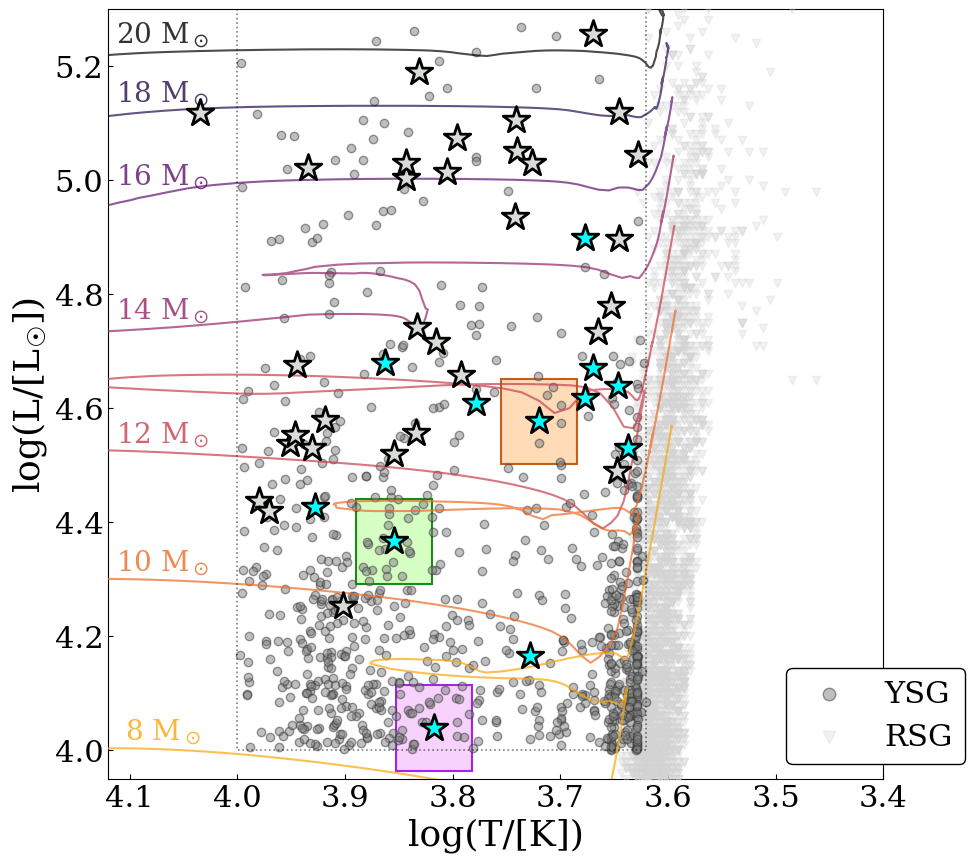

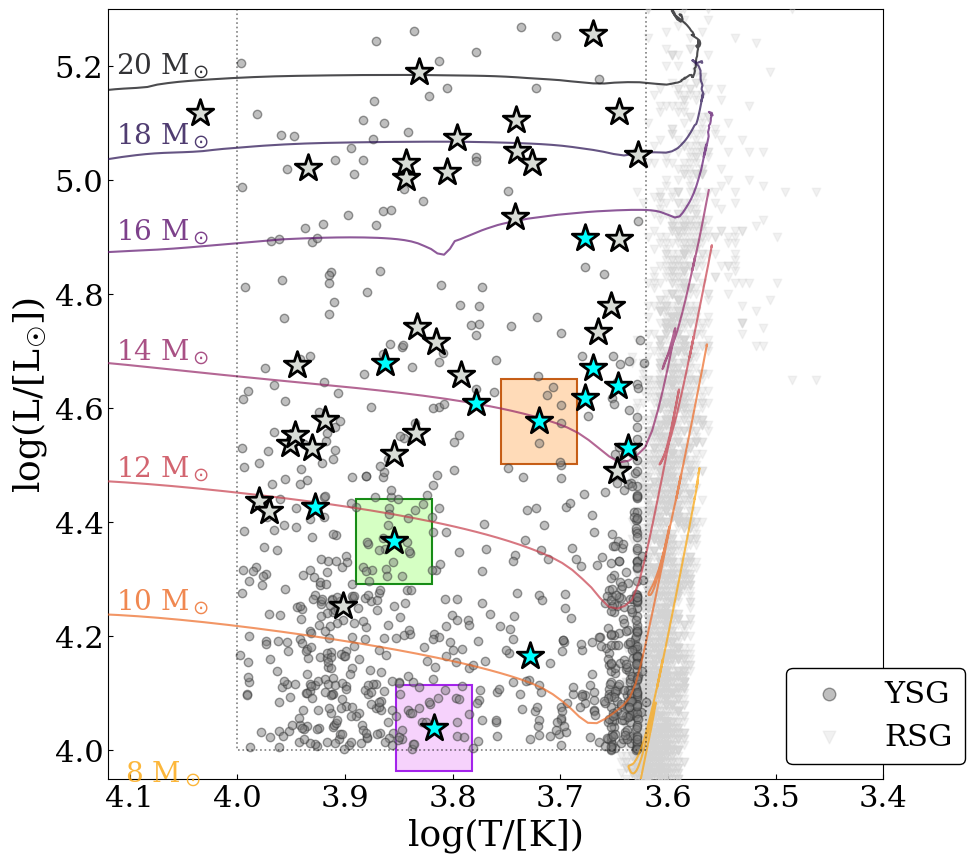

In [ ]:
def plot_hrd(evol_track_files,
    *,
    open_file_func=None,
    var_df=None,
    rsg_smc_df=None,
    rsg_lmc_df=None,
    boxes=None,
    box_styles=None,
    proposed_indices=None,
    individual_plotter_func=None,
    figsize=(10, 10),
    width_ratios=(1.15, 1.0),
    hrd_xlim=(4.12, 3.40),
    hrd_ylim=(3.93, 5.48),
    ysg_box=(3.62, 4.00, 4.00, 5.48),
    savepath=None,
    dpi=300,
    report=False,
):
    if open_file_func is None:
        open_file_func = Open_File
    if var_df is None:
        var_df = stats
    if rsg_smc_df is None:
        rsg_smc_df = rsg_smc
    if rsg_lmc_df is None:
        rsg_lmc_df = rsg_lmc
    if boxes is None:
        boxes = [box3, box1, box2]
    if proposed_indices is None:
        proposed_indices = proposed
    if individual_plotter_func is None:
        individual_plotter_func = individual_plotter

    if box_styles is None:
        box_styles = [
            {"border_color": "xkcd:burnt orange", "bg": "xkcd:light peach", "border_width": 3.0},
            {"border_color": "green", "bg": "xkcd:very light green", "border_width": 3.0},
            {"border_color": "xkcd:violet", "bg": "xkcd:very light purple", "border_width": 3.0}
        ]

    if len(boxes) != 3:
        raise ValueError("Expected exactly 3 boxes (e.g., [box1, box2, box3])")
    # fig = plt.figure(figsize=figsize)
    fig, ax_hrd = plt.subplots(figsize=figsize)
    # Slightly larger gap between the left and right columns.
    gs = GridSpec(1, 2, figure=fig, width_ratios=width_ratios, wspace=0.31)

    # -----------------------------
    # Left panel: HRD
    # -----------------------------
    # ax_hrd = fig.add_subplot(gs[0, 0])

    cmap = cm.inferno
    norm = mcolors.Normalize(vmin=0, vmax=len(evol_track_files) - 1)
    new_cmap = truncate_colormap(cmap, 0.0, 0.8, n=len(evol_track_files))

    for i, file_i in enumerate(evol_track_files):
        df_i = open_file_func(file_i)
        phase_i = get_phase(df_i)
        color = new_cmap(norm(i))

        ax_hrd.plot(
            phase_i["log_Teff"],
            phase_i["log_L"],
            "-",
            color=color,
            alpha=0.7,
            zorder=17,
        )

        x_label = 4.069
        idx_near = (phase_i["log_Teff"] - x_label).abs().idxmin()
        y_label = phase_i.loc[idx_near, "log_L"]

        # Mass annotation
        ax_hrd.annotate(
            str(int(file_i.split("/")[-1].split(".track")[0][1:3])) + r" M$_\odot$",
            xy=(x_label, y_label),
            xytext=(0, 2),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=20,
            color=color,
            zorder=20,
            alpha=0.8,
            annotation_clip=False,
        )


    x0, x1, y0, y1 = ysg_box
    mask = var_df[
        (var_df["logT"] > x0)
        & (var_df["logT"] < x1)
        & (var_df["logL"] > y0)
        & (var_df["logL"] < y1)
        # & (var_df["alarm_level_flag"] == 0)
        # & (var_df["alarm_level_flag"].notna())
    ]
    # ax_hrd.fill_betweenx([y0, y1], x0, x1, color="xkcd:yellow tan", alpha=0.2, zorder=1)
    ax_hrd.add_patch(Rectangle((3.62, 4.0),0.38,1.6,facecolor='none',edgecolor='black',
                alpha=0.5,
                zorder=20,
                linewidth=1.2,
                linestyle='dotted',
            ))

    ax_hrd.scatter(
        mask["logT"],
        mask["logL"],
        alpha=0.5,
        # color="xkcd:butter yellow",
        color='grey',
        # edgecolors="xkcd:orangey yellow",
        edgecolor='xkcd:dark grey',
        label="YSG",
        zorder=8,
    )

    # RSG comparison samples
    ax_hrd.scatter(
        np.log10(rsg_smc_df["Temp"]),
        rsg_smc_df["LogLum"],
        alpha=0.3,
        c="lightgrey",
        label="RSG",
        zorder=6,
        marker="v",
    )
    ax_hrd.scatter(
        np.log10(rsg_lmc_df["Temp"]),
        rsg_lmc_df["LogLum"],
        alpha=0.3,
        c="lightgrey",
        zorder=6,
        marker="v",
    )

    # sn_zorder = 9
    # sn_color = "xkcd:red"
    # sn_ecolor = "black"
    # # ax_hrd.errorbar(3.825, 5.0, xerr=0.025, yerr=0.05, fmt="o", color=sn_color, ecolor=sn_ecolor, label="SNIIb \nProgenitor", zorder=sn_zorder)
    # # ax_hrd.errorbar(3.72, 5.17, xerr=0.08, yerr=0.04, fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)
    # # ax_hrd.errorbar(3.98, 5.14, xerr=[[0.16], [0.21]], yerr=[[0.39], [0.22]], fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)
    # # ax_hrd.errorbar(3.63, 4.94, xerr=0.01, yerr=0.06, fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)
    # # ax_hrd.errorbar(3.78, 4.92, xerr=0.02, yerr=0.2, fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)
    # # ax_hrd.errorbar(3.63, 5.1, xerr=0.05, yerr=0.3, fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)
    # ax_hrd.scatter(3.825, 5.0, marker="X", s=200, color=sn_color, edgecolors=sn_ecolor, zorder=sn_zorder + 1, label="Known SN \nProgenitor")
    # ax_hrd.scatter(3.72, 5.17, marker="X", s=200, color=sn_color, edgecolors=sn_ecolor, zorder=sn_zorder + 1)
    # ax_hrd.scatter(3.98, 5.14, marker="X", s=200, color=sn_color, edgecolors=sn_ecolor, zorder=sn_zorder + 1)
    # ax_hrd.scatter(3.63, 4.94, marker="X", s=200, color=sn_color, edgecolors=sn_ecolor, zorder=sn_zorder + 1)
    # ax_hrd.scatter(3.78, 4.92, marker="X", s=200, color=sn_color, edgecolors=sn_ecolor, zorder=sn_zorder + 1)

    # Proposed targets
    for star_idx in proposed_indices:
        if star_idx not in var_df.index:
            continue
        if star_idx == 307:
            ax_hrd.scatter(
                var_df.loc[star_idx, "logT"],
                var_df.loc[star_idx, "logL"],
                marker="*",
                s=400,
                c="cyan",
                linewidths=2.0,
                edgecolors="black",
                label="Proposed \nTarget",
                zorder=100,
            )
        else:
            ax_hrd.scatter(
                var_df.loc[star_idx, "logT"],
                var_df.loc[star_idx, "logL"],
                marker="*",
                s=400,
                c="cyan",
                linewidths=2.0,
                edgecolors="black",
                zorder=100,
            )
    for star in highL_cands:
        if star not in var_df.index:
            continue
        ax_hrd.scatter(
            var_df.loc[star, "logT"],
            var_df.loc[star, "logL"],
            marker="*",
            s=400,
            c="xkcd:light grey",
            linewidths=2.0,
            edgecolors="black",
            zorder=100,
        )

    box_star_indices = [307, 780, 716]
    box_star_colours = ["xkcd:very light green", "xkcd:very light purple", "xkcd:light peach"]
    box_star_ecolors = ["green", "xkcd:violet", "xkcd:burnt orange"]
    box_dx = 0.06 # original
    box_dy = 0.14 # original
    box_dx = 0.07
    box_dy = 0.15
    for box_idx, facecol, ecol in zip(box_star_indices, box_star_colours, box_star_ecolors):
        if box_idx not in var_df.index:
            continue
        x0b = var_df.loc[box_idx, "logT"]
        y0b = var_df.loc[box_idx, "logL"]
        if pd.isna(x0b) or pd.isna(y0b):
            continue
        ax_hrd.add_patch(
            Rectangle(
                (x0b - box_dx / 2, y0b - box_dy / 2),
                box_dx,
                box_dy,
                facecolor=facecol,
                edgecolor=ecol,
                alpha=0.9,
                zorder=2,
                linewidth=1.5
            )
        )

    ax_hrd.invert_xaxis()
    ax_hrd.set_xlim(*hrd_xlim)
    ax_hrd.set_ylim(*hrd_ylim)
    ax_hrd.set_ylim(3.95,5.3)
    ax_hrd.tick_params(axis="both", direction="in", labelsize=22)
    ax_hrd.set_xlabel("log(T/[K])", fontsize=26)
    ax_hrd.set_ylabel("log(L/[L$_☉$])", fontsize=26)

    # Fixed-order legend
    handles, labels = ax_hrd.get_legend_handles_labels()
    label_to_handle = {}
    for h, lab in zip(handles, labels):
        if lab and (lab not in label_to_handle):
            label_to_handle[lab] = h

    wanted = ["YSG", "RSG", "Proposed \nCandidate"] #"Known SN \nProgenitor",
    ordered_handles = [label_to_handle[l] for l in wanted if l in label_to_handle]
    ordered_labels = [l for l in wanted if l in label_to_handle]

    leg = ax_hrd.legend(
        ordered_handles,
        ordered_labels,
        bbox_to_anchor=(1.125, 0.0),
        loc="lower right",
        title_fontsize=16,
        fontsize=22,
        markerscale=1.5,
        frameon=True,
        framealpha=1.0,
        facecolor="white",
        edgecolor="black",
    )
    leg.set_zorder(200)

    fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
plot_hrd(#evol_files_smc[:-3][::-1],
    evol_files_smc[:7][::-1],
    savepath="./figs/hr_diagrams/plot_HRD_cropped_allYSGs_newTs.png", dpi=600,
    report=False)
plot_hrd(evol_files_lmc[:7][::-1],savepath="./figs/hr_diagrams/plot_HRD_cropped_allYSGs_newTs.png", dpi=600,
    report=False)

9


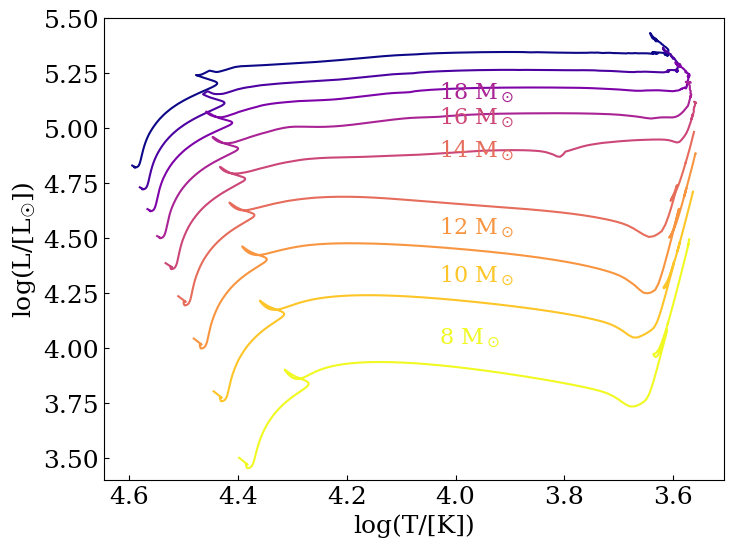

In [ ]:
def plot_evol_tracks_handmade(files, ax, lmc=True):
    '''
    plots the evolutionary tracks for a list of files on a given axis. The lmc parameter is used to determine whether to plot the LMC or SMC tracks.
    '''
    plt.figure(figsize=(8, 6))
    # Set the color map
    cmap = cm.plasma 
    norm = mcolors.Normalize(vmin=0, vmax=len(files) - 1) 
    norm = mcolors.Normalize(vmin=0, vmax=8)
    print(len(files))
    if lmc:
        for i, file_i in enumerate(files): 
            if i > 1:
                df_i = Open_File(file_i)
                MS_i = Get_MS(df_i)
                RGB_i = get_RGB(df_i)
                phase_i = get_phase(df_i)
                color = cmap(norm(i))
                ax.plot(phase_i['log_Teff'],phase_i['log_L'],"-",color=color) #, label = str(int(file_i.split('/')[-1].split('.track')[0][1:3]))+r" M$_\odot$")

    if not lmc:
        for i, file_i in enumerate(files): 
            # if i > 2:
            df_i = Open_File(file_i)
            MS_i = Get_MS(df_i)
            RGB_i = get_RGB(df_i)
            phase_i = get_phase(df_i)
            color = cmap(norm(i))
            ax.plot(phase_i['log_Teff'],phase_i['log_L'],"-",color=color, label = str(int(file_i.split('/')[-1].split('.track')[0][1:3]))+r" M$_\odot$")


        # This is a way to annotate the curve with stellar masses more iteratively (I just set them all manually below because I wanted to control the placement of the text, but this is a more automated way to do it)
        # ax.annotate(str(int(file_i.split('/')[-1].split('.track')[0][1:3])) + r" M$_\odot$",
        #             xy=(x_label, y_label), xytext=(x_label-0.25, y_label+0.48), 
        #             textcoords='data', ha='center', fontsize=11, color=cmap(norm(i)))

    plt.gca().invert_xaxis()

    if lmc:
        # annotate the curve with stellar masses, with correct positions to look nice with the LMC tracks
        plt.text(4.33, 4.25, '10 M$_\\odot$', color = cmap(norm(7)), fontsize=16)
        plt.text(4.34, 4.50, '12 M$_\\odot$', color = cmap(norm(6)), fontsize=16)
        plt.text(4.35, 4.70, '14 M$_\\odot$', color = cmap(norm(5)), fontsize=16)
        plt.text(4.37, 4.86, '16 M$_\\odot$', color = cmap(norm(4)), fontsize=16)
        plt.text(4.39, 5.00, '18 M$_\\odot$', color = cmap(norm(3)), fontsize=15)
        plt.text(4.43, 5.12, '20 M$_\\odot$', color = cmap(norm(2)), fontsize=16)
        plt.text(4.03, 5.28, '22 M$_\\odot$', color = cmap(norm(1)), fontsize=16)
        plt.text(4.03, 5.36, '24 M$_\\odot$', color = cmap(norm(0)), fontsize=16)
    else:
        # annotate the curve with stellar masses, with correct positions to look nice with the SMC tracks
        plt.text(4.03, 4.02, '8 M$_\\odot$', color = cmap(norm(8)), fontsize=16)
        plt.text(4.03, 4.3, '10 M$_\\odot$', color = cmap(norm(7)), fontsize=16)
        plt.text(4.03, 4.52, '12 M$_\\odot$', color = cmap(norm(6)), fontsize=16)
        plt.text(4.03, 4.87, '14 M$_\\odot$', color = cmap(norm(5)), fontsize=16)
        plt.text(4.03, 5.02, '16 M$_\\odot$', color = cmap(norm(4)), fontsize=16)
        plt.text(4.03, 5.13, '18 M$_\\odot$', color = cmap(norm(3)), fontsize=16)


    # Uncomment this if you want the actual observed Type IIb supernovae shown on the HRD!
    # sn_zorder = 9
    # sn_color = "xkcd:white"
    # sn_ecolor = "white"
    # plt.errorbar(3.825, 5.0, xerr=0.025, yerr=0.05, fmt="o", color=sn_color, ecolor=sn_ecolor, label="YSG SNIIb \nProgenitor", zorder=sn_zorder)
    # plt.errorbar(3.72, 5.17, xerr=0.08, yerr=0.04, fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)
    # plt.errorbar(3.98, 5.14, xerr=[[0.16], [0.21]], yerr=[[0.39], [0.22]], fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)
    # plt.errorbar(3.63, 4.94, xerr=0.01, yerr=0.06, fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)
    # plt.errorbar(3.78, 4.92, xerr=0.02, yerr=0.2, fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)
    # plt.errorbar(3.63, 5.1, xerr=0.05, yerr=0.3, fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)


    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)

    plt.tick_params(axis='both', direction='in')
    plt.ylim(3.4, 5.5)
    plt.xlabel('log(T/[K])', fontsize=18)
    plt.ylabel('log(L/[L$_☉$])', fontsize=18)
    # plt.savefig(f'HR_diagram_smc.png', dpi=300, bbox_inches='tight')

plot_evol_tracks_handmade(evol_files_lmc[:-3][::-1], plt, lmc=False)

In [9]:
smcTs = [3.6881057268722466,
3.6734214390602054, 
3.6616740088105724, 
3.6279001468428778, 
3.6249632892804695]
smcLs = [3.8632380875399104,
4.160539681256652,
4.395445176413531,
4.832266364897817,
 4.986405582723734]

lmcTs = [3.6755555555555555, 
3.671111111111111, 
3.6503703703703705, 
3.6444444444444444, 
3.5925925925925926]

lmcLs = [3.7344322344322345,
4.049450549450549,
4.250915750915751,
4.507326007326007,
4.935897435897436]


80000.0
100000.0
120000.0
140000.0
Plotting ../MIST_models_LMC_v2.5/0080000M.track.eep
Plotting ../MIST_models_LMC_v2.5/0100000M.track.eep
Plotting ../MIST_models_LMC_v2.5/0120000M.track.eep
Plotting ../MIST_models_LMC_v2.5/0140000M.track.eep
Plotting ../MIST_models_LMC_v2.5/0160000M.track.eep
Plotting ../MIST_models_LMC_v2.5/0180000M.track.eep
Plotting ../MIST_models_LMC_v2.5/0200000M.track.eep
Plotting ../MIST_models_LMC_v2.5/0220000M.track.eep
Plotting ../MIST_models_LMC_v2.5/0240000M.track.eep
Plotting ../MIST_models_LMC_v2.5/0260000M.track.eep
Plotting ../MIST_models_LMC_v2.5/0280000M.track.eep
Plotting ../MIST_models_LMC_v2.5/0300000M.track.eep


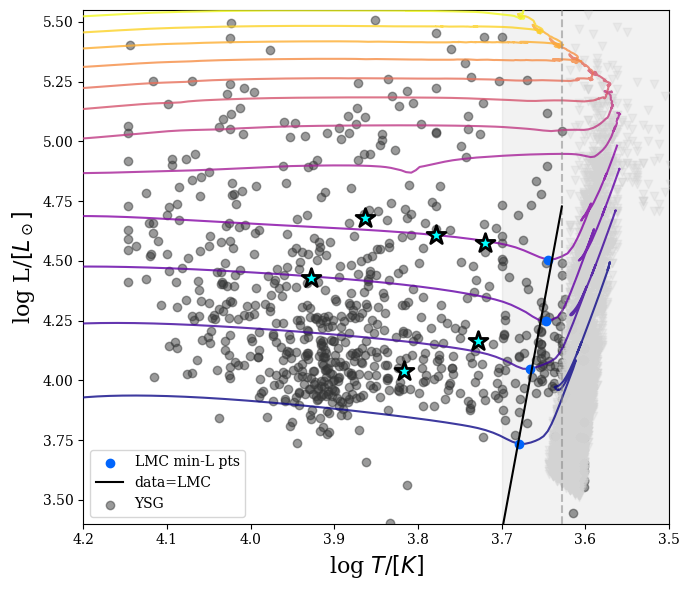

In [10]:
def get_min_L_in_Trange(df_i, logT_min=3.5, logT_max=3.7):
    """
    For a single (already-loaded) track, find the point of minimum log_L
    within a logT window. Returns (log_Teff, log_L) at that minimum,
    or (nan, nan) if the track never crosses this logT range.
    """
    phase_i = get_phase(df_i)
    in_range = phase_i[(phase_i['log_Teff'] >= logT_min) & (phase_i['log_Teff'] <= logT_max)]
    if len(in_range) == 0:
        return np.nan, np.nan
    idx_min = in_range['log_L'].idxmin()
    return phase_i.loc[idx_min, 'log_Teff'], phase_i.loc[idx_min, 'log_L']

def collect_min_L_points(files, logT_min=3.5, logT_max=3.7, open_file_func=Open_File):
    """
    Loop over track files, pulling the min-L point in the logT window
    for each. Returns arrays of mass, logT, logL (tracks with no
    crossing are skipped).
    """
    masses, logTs, logLs = [], [], []
    for file_i in files:
        df_i = open_file_func(file_i)
        logT_pt, logL_pt = get_min_L_in_Trange(df_i, logT_min, logT_max)
        if np.isnan(logT_pt):
            continue
        if logL_pt > 4.85:
            continue
        mass = float(file_i.split('/')[-1].split('M')[0])
        print(mass)
        # if mass == 140000.0:
        #     continue
        # if logT_pt < np.log10(4250):
        #     continue
        masses.append(mass)
        logTs.append(logT_pt)
        logLs.append(logL_pt)
    return np.array(masses), np.array(logTs), np.array(logLs)

def plot_min_L_fit(files, label, color, logT_min=3.5, logT_max=3.7, open_file_func=Open_File):

    plt.rcParams['font.family'] = 'serif'
    masses, logTs, logLs = collect_min_L_points(files, logT_min, logT_max, open_file_func)

    # if label == 'SMC':
    #     logTs = smcTs
    #     logLs = smcLs
    # elif label == 'LMC':
    #     logTs = lmcTs
    #     logLs = lmcLs

    # coeffs = np.polyfit(logTs, logLs, 1)   # [slope, intercept]
    # fit_line = np.poly1d(coeffs)
    # print(f"{label}: log_L = {coeffs[0]:.3f} * log_Teff + {coeffs[1]:.3f}  (n={len(logTs)})")

    fig, ax = plt.subplots(figsize=(7, 6))

    ###### plotting evol tracks
    color_map = cm.plasma
    norm = mcolors.Normalize(vmin=0, vmax=len(files) - 1)

    for file_i in files:
        print(f"Plotting {file_i}")
        phase_i = get_phase(open_file_func(file_i))
        ###### make some tracks disappear
        # if file_i.split('/')[-1].split('M')[0] == '0140000' or file_i.split('/')[-1].split('M')[0] == '0150000':
        #     continue
        # if file_i.split('/')[-1].split('M')[0] == '0080000':
        #     continue
        ax.plot(phase_i['log_Teff'], phase_i['log_L'], '-', color=color_map(norm(files.index(file_i))), alpha=0.8, zorder=7)


    ####### plotting min-L points and the fit line
    ax.scatter(logTs, logLs, color=color, label=f'{label} min-L pts', zorder=8)

    # x_fit = np.linspace(logTs.min(), logTs.max(), 50)

    linefit = np.polynomial.Polynomial.fit(logTs, logLs, 1)
    intercept, slope = linefit.convert().coef
    xarray = np.linspace(3.628, 3.7, 100)
    #plot fit
    ax.plot(xarray, linefit(xarray), 'k-', label=f"data={label}", zorder=10) # slope={slope:.3f}, intercept={intercept:.3f}", 

    ax.axvspan(logT_min, logT_max, color='gray', alpha=0.1, zorder=0)

    ###### plotting RSGs
    if label == 'LMC':
        ax.scatter(
            np.log10(rsg_lmc["Temp"]),
            rsg_lmc["LogLum"],
            alpha=0.3,
            c="lightgrey",
            zorder=6,
            marker="v",
        )
    if label == 'SMC':
        ax.scatter(
            np.log10(rsg_smc["Temp"]),
            rsg_smc["LogLum"],
            alpha=0.3,
            c="lightgrey",
            zorder=6,
            marker="v",
        )
    ####### plotting YSGs
    if label == 'SMC':
        ax.scatter(stats[stats['RA'] < 40.0]['logT'], stats[stats['RA'] < 40.0]['logL'], alpha=0.5, color='xkcd:dark grey', edgecolors='xkcd:dark grey', label='YSG', zorder=0)
    if label == 'LMC':
        ax.scatter(stats[stats['RA'] >= 40.0]['logT'], stats[stats['RA'] >= 40.0]['logL'], alpha=0.5, color='xkcd:dark grey', edgecolors='xkcd:dark grey', label='YSG', zorder=0)

    for star_idx in proposed:
        # check if in SMC or LMC
        if stats.loc[star_idx, 'RA'] < 40.0 and label == 'SMC' or stats.loc[star_idx, 'RA'] >= 40.0 and label == 'LMC':
            ax.scatter(
                stats.loc[star_idx, "logT"],
                stats.loc[star_idx, "logL"],
                marker="*",
                s=200,
                c="cyan",
                linewidths=2.0,
                edgecolors="black",
                zorder=100,
                )

    #vertical line at 3.6
    ax.axvline(np.log10(4250), color='gray', linestyle='--', alpha=0.5, zorder=7)

    ax.set_ylim(3.4, 5.55)
    ax.set_xlim(3.5, 4.2)
    ax.invert_xaxis()
    ax.set_xlabel('log $T/[K]$', fontsize=16)
    ax.set_ylabel('log L/$[L_\\odot]$', fontsize=16)
    # ax.set_title(f'{label}: minimum-L points')
    ax.legend()
    plt.tight_layout()
    plt.savefig('./figs/hr_diagrams/plot_LMC_minL_fit.png', dpi=600, bbox_inches='tight')
    plt.show()
    

    return masses, logTs, logLs#, coeffs

# LMC
masses_lmc, logT_lmc, logL_lmc = plot_min_L_fit(
    evol_files_lmc, label='LMC', color='xkcd:bright blue'
)

# # SMC
# masses_smc, logT_smc, logL_smc = plot_min_L_fit(
#     evol_files_smc, label='SMC', color='xkcd:bright red'
# )

In [11]:
print(len(rsg_smc), len(rsg_lmc))

1678 4075


# My tracks

LMC: log_L = -34.596 * log_Teff + 130.425  (n=11)


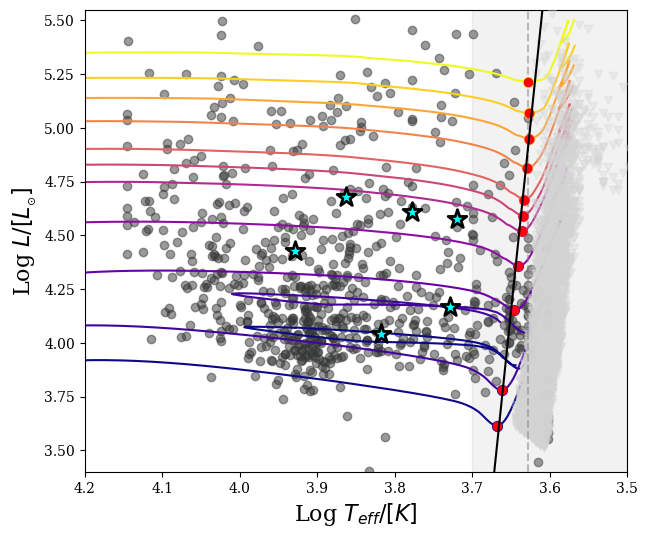

In [12]:
import mesa_reader as mr
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd
import matplotlib.cm as cm
import matplotlib.colors as mcolors

masses = [8, 9, 10, 12, 14, 15, 16, 18, 20, 22, 25]
color_map = cm.plasma
norm = mcolors.Normalize(vmin=0, vmax=len(masses) - 1)

def get_min_L_in_Trange_mytrack(df, logT_min=3.5, logT_max=3.7):
    """
    For a single (already-loaded) track, find the point of minimum log_L
    within a logT window. Returns (log_Teff, log_L) at that minimum,
    or (nan, nan) if the track never crosses this logT range.
    """
    log_Teff = np.asarray(df.log_Teff)
    log_L = np.asarray(df.log_L)

    mask = (log_Teff >= logT_min) & (log_Teff <= logT_max)
    if not np.any(mask):
        return np.nan, np.nan

    # index of the minimum log_L *within* the masked subset
    idx_local = np.argmin(log_L[mask])
    # map back to the index in the full array
    idx_min = np.where(mask)[0][idx_local]

    return log_Teff[idx_min], log_L[idx_min]


logTs = []
logLs = []

fig, ax = plt.subplots(figsize=(7, 6))
for mass in masses:
    postMSlogdir = mr.MesaLogDir(f'../../ysg_mesa_LMC/{mass}M_alpha2.1_wind0.5/LOGS')
    h_postMS = postMSlogdir.history_data

    # only want the parts at log_Teff < 4.25 in the history table
    history_mask = h_postMS.log_Teff < 4.25
    log_Teff = h_postMS.log_Teff[history_mask]
    log_L = h_postMS.log_L[history_mask]
    ax.plot(log_Teff, log_L, color=color_map(norm(masses.index(mass))), zorder=1)


    # plot the minimum-L point in the logT range 3.5-3.7
    # define range:
    in_range_mask = (h_postMS.log_Teff >= 3.5) & (h_postMS.log_Teff <= 3.7)
    logT_pt, logL_pt = get_min_L_in_Trange_mytrack(h_postMS, logT_min=3.5, logT_max=3.7)
    ax.scatter(logT_pt, logL_pt, color=color_map(norm(masses.index(mass))), s=50, zorder=2)

    logTs.append(logT_pt)
    logLs.append(logL_pt)


ax.scatter(stats[stats['RA'] >= 40.0]['logT'], stats[stats['RA'] >= 40.0]['logL'], alpha=0.5, color='xkcd:dark grey', edgecolors='xkcd:dark grey', label='YSG', zorder=0)
    
for star_idx in proposed:
    # check if in SMC or LMC
    if stats.loc[star_idx, 'RA'] >= 40.0:
        ax.scatter(
            stats.loc[star_idx, "logT"],
            stats.loc[star_idx, "logL"],
            marker="*",
            s=200,
            c="cyan",
            linewidths=2.0,
            edgecolors="black",
            zorder=100,
            )

ax.scatter(
            np.log10(rsg_lmc["Temp"]),
            rsg_lmc["LogLum"],
            alpha=0.3,
            c="lightgrey",
            zorder=6,
            marker="v",
            )

#vertical line at 3.6
ax.axvline(np.log10(4250), color='gray', linestyle='--', alpha=0.5, zorder=7)

ax.scatter(logTs, logLs, color='xkcd:bright red', label=f'LMC min-L pts', zorder=8)

# x_fit = np.linspace(logTs.min(), logTs.max(), 50)

linefit = np.polynomial.Polynomial.fit(logTs, logLs, 1)
intercept, slope = linefit.convert().coef
print(f"LMC: log_L = {slope:.3f} * log_Teff + {intercept:.3f}  (n={len(logTs)})")
# xarray = np.linspace(3.628, 3.7, 100)
xarray = np.linspace(3.6, 3.7, 100)
#plot fit
ax.plot(xarray, linefit(xarray), 'k-', zorder=10) # slope={slope:.3f}, intercept={intercept:.3f}", 
logT_min=3.5
logT_max=3.7
ax.axvspan(logT_min, logT_max, color='gray', alpha=0.1, zorder=0)
ax.set_ylim(3.4, 5.55)
ax.set_xlim(3.5, 4.2)
ax.invert_xaxis()
# ax.set_xlim(4.33, 3.55)
# ax.set_ylim(3.42, 5.55)
ax.set_xlabel('Log $T_{eff}/[K]$', fontsize=16)
ax.set_ylabel('Log $L/[L_{_{\\odot}}]$', fontsize=16)
plt.savefig('./figs/hr_diagrams/plot_LMC_minL_fit_mytracks.png', dpi=600, bbox_inches='tight')

SMC: log_L = -30.885 * log_Teff + 116.746  (n=11)


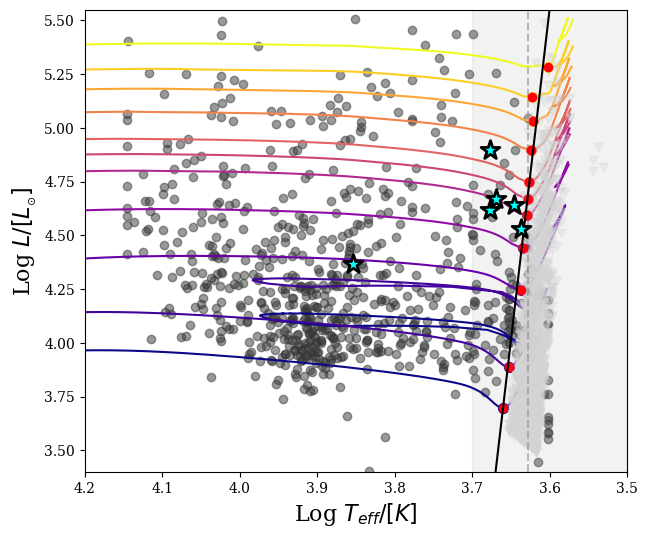

In [13]:
import mesa_reader as mr
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd
import matplotlib.cm as cm
import matplotlib.colors as mcolors

masses = [8, 9, 10, 12, 14, 15, 16, 18, 20, 22, 25]
color_map = cm.plasma
norm = mcolors.Normalize(vmin=0, vmax=len(masses) - 1)

def get_min_L_in_Trange_mytrack(df, logT_min=3.5, logT_max=3.7):
    """
    For a single (already-loaded) track, find the point of minimum log_L
    within a logT window. Returns (log_Teff, log_L) at that minimum,
    or (nan, nan) if the track never crosses this logT range.
    """
    log_Teff = np.asarray(df.log_Teff)
    log_L = np.asarray(df.log_L)

    mask = (log_Teff >= logT_min) & (log_Teff <= logT_max)
    if not np.any(mask):
        return np.nan, np.nan

    # index of the minimum log_L *within* the masked subset
    idx_local = np.argmin(log_L[mask])
    # map back to the index in the full array
    idx_min = np.where(mask)[0][idx_local]

    return log_Teff[idx_min], log_L[idx_min]


logTs = []
logLs = []

fig, ax = plt.subplots(figsize=(7, 6))
for mass in masses:
    postMSlogdir = mr.MesaLogDir(f'../../ysg_mesa_SMC/{mass}M_alpha2.1_wind0.5/LOGS')
    h_postMS = postMSlogdir.history_data

    # only want the parts at log_Teff < 4.25 in the history table
    history_mask = h_postMS.log_Teff < 4.25
    log_Teff = h_postMS.log_Teff[history_mask]
    log_L = h_postMS.log_L[history_mask]
    ax.plot(log_Teff, log_L, color=color_map(norm(masses.index(mass))), zorder=1)


    # plot the minimum-L point in the logT range 3.5-3.7
    # define range:
    in_range_mask = (h_postMS.log_Teff >= 3.5) & (h_postMS.log_Teff <= 3.7)
    logT_pt, logL_pt = get_min_L_in_Trange_mytrack(h_postMS, logT_min=3.5, logT_max=3.7)
    ax.scatter(logT_pt, logL_pt, color=color_map(norm(masses.index(mass))), s=50, zorder=2)

    logTs.append(logT_pt)
    logLs.append(logL_pt)


ax.scatter(stats[stats['RA'] >= 40.0]['logT'], stats[stats['RA'] >= 40.0]['logL'], alpha=0.5, color='xkcd:dark grey', edgecolors='xkcd:dark grey', label='YSG', zorder=0)
    
for star_idx in proposed:
    # check if in SMC or LMC
    if stats.loc[star_idx, 'RA'] < 40.0:
        ax.scatter(
            stats.loc[star_idx, "logT"],
            stats.loc[star_idx, "logL"],
            marker="*",
            s=200,
            c="cyan",
            linewidths=2.0,
            edgecolors="black",
            zorder=100,
            )

ax.scatter(
            np.log10(rsg_smc["Temp"]),
            rsg_smc["LogLum"],
            alpha=0.3,
            c="lightgrey",
            zorder=6,
            marker="v",
            )

#vertical line at 3.6
ax.axvline(np.log10(4250), color='gray', linestyle='--', alpha=0.5, zorder=7)

ax.scatter(logTs, logLs, color='xkcd:bright red', label=f'SMC min-L pts', zorder=8)

# x_fit = np.linspace(logTs.min(), logTs.max(), 50)

linefit = np.polynomial.Polynomial.fit(logTs, logLs, 1)
intercept, slope = linefit.convert().coef
print(f"SMC: log_L = {slope:.3f} * log_Teff + {intercept:.3f}  (n={len(logTs)})")
# xarray = np.linspace(3.628, 3.7, 100)
xarray = np.linspace(3.6, 3.7, 100)
#plot fit
ax.plot(xarray, linefit(xarray), 'k-', zorder=10) # slope={slope:.3f}, intercept={intercept:.3f}", 
logT_min=3.5
logT_max=3.7
ax.axvspan(logT_min, logT_max, color='gray', alpha=0.1, zorder=0)
ax.set_ylim(3.4, 5.55)
ax.set_xlim(3.5, 4.2)
ax.invert_xaxis()
# ax.set_xlim(4.33, 3.55)
# ax.set_ylim(3.42, 5.55)
ax.set_xlabel('Log $T_{eff}/[K]$', fontsize=16)
ax.set_ylabel('Log $L/[L_{_{\\odot}}]$', fontsize=16)
plt.savefig('./figs/hr_diagrams/plot_SMC_minL_fit_mytracks.png', dpi=600, bbox_inches='tight')

# nicer version

SMC: log_L = -30.885 * log_Teff + 116.746  (n=11)


Text(0, 0.5, 'Log $L/[L_{_{\\odot}}]$')

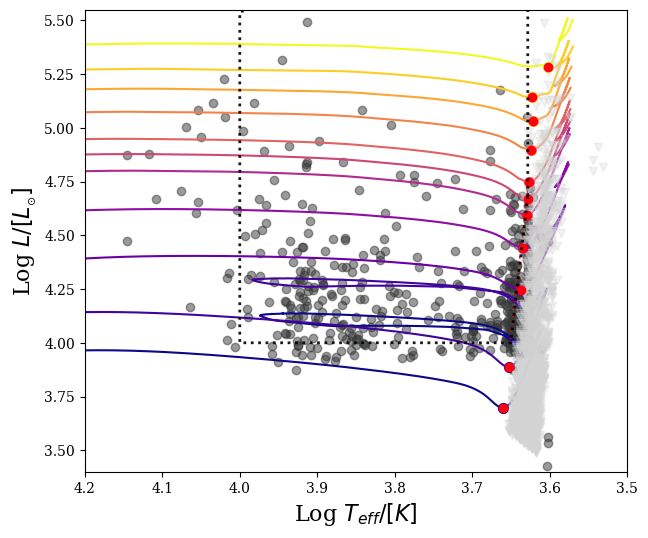

In [14]:
masses = [8, 9, 10, 12, 14, 15, 16, 18, 20, 22, 25]
color_map = cm.plasma
norm = mcolors.Normalize(vmin=0, vmax=len(masses) - 1)

def get_min_L_in_Trange_mytrack(df, logT_min=3.5, logT_max=3.7):
    """
    For a single (already-loaded) track, find the point of minimum log_L
    within a logT window. Returns (log_Teff, log_L) at that minimum,
    or (nan, nan) if the track never crosses this logT range.
    """
    log_Teff = np.asarray(df.log_Teff)
    log_L = np.asarray(df.log_L)

    mask = (log_Teff >= logT_min) & (log_Teff <= logT_max)
    if not np.any(mask):
        return np.nan, np.nan

    # index of the minimum log_L *within* the masked subset
    idx_local = np.argmin(log_L[mask])
    # map back to the index in the full array
    idx_min = np.where(mask)[0][idx_local]

    return log_Teff[idx_min], log_L[idx_min]


logTs = []
logLs = []

fig, ax = plt.subplots(figsize=(7, 6))
for mass in masses:
    postMSlogdir = mr.MesaLogDir(f'../../ysg_mesa_SMC/{mass}M_alpha2.1_wind0.5/LOGS')
    h_postMS = postMSlogdir.history_data

    # only want the parts at log_Teff < 4.25 in the history table
    history_mask = h_postMS.log_Teff < 4.25
    log_Teff = h_postMS.log_Teff[history_mask]
    log_L = h_postMS.log_L[history_mask]
    ax.plot(log_Teff, log_L, color=color_map(norm(masses.index(mass))), zorder=1)


    # plot the minimum-L point in the logT range 3.5-3.7
    # define range:
    in_range_mask = (h_postMS.log_Teff >= 3.5) & (h_postMS.log_Teff <= 3.7)
    logT_pt, logL_pt = get_min_L_in_Trange_mytrack(h_postMS, logT_min=3.5, logT_max=3.7)
    ax.scatter(logT_pt, logL_pt, color=color_map(norm(masses.index(mass))), s=50, zorder=2)

    logTs.append(logT_pt)
    logLs.append(logL_pt)


ax.scatter(stats[stats['RA'] < 40.0]['logT'], stats[stats['RA'] < 40.0]['logL'], alpha=0.5, color='xkcd:dark grey', edgecolors='xkcd:dark grey', label='YSG', zorder=0)
    
# for star_idx in proposed:
    # check if in SMC or LMC
    # if stats.loc[star_idx, 'RA'] < 40.0:
    #     ax.scatter(
    #         stats.loc[star_idx, "logT"],
    #         stats.loc[star_idx, "logL"],
    #         marker="*",
    #         s=200,
    #         c="cyan",
    #         linewidths=2.0,
    #         edgecolors="black",
    #         zorder=100,
    #         )

ax.scatter(
            np.log10(rsg_smc["Temp"]),
            rsg_smc["LogLum"],
            alpha=0.3,
            c="lightgrey",
            zorder=6,
            marker="v",
            )

#vertical line at 3.6
# ax.axvline(np.log10(4250), color='gray', linestyle='--', alpha=0.5, zorder=7)

ax.scatter(logTs, logLs, color='xkcd:bright red', label=f'SMC min-L pts', zorder=8)

# x_fit = np.linspace(logTs.min(), logTs.max(), 50)

linefit_SMC = np.polynomial.Polynomial.fit(logTs, logLs, 1)
intercept, slope = linefit.convert().coef
print(f"SMC: log_L = {slope:.3f} * log_Teff + {intercept:.3f}  (n={len(logTs)})")
# xarray = np.linspace(3.628, 3.7, 100)
xarray = np.linspace(3.6, 3.7, 100)
#plot fit
# ax.plot(xarray, linefit(xarray), 'k-', zorder=10) # slope={slope:.3f}, intercept={intercept:.3f}", 
logT_min=3.5
logT_max=3.7


from matplotlib.patches import Polygon

from matplotlib.patches import Polygon

# Box definition (same as before)
x0, y0 = np.log10(4250), 4.0
width, height = 4.0 - np.log10(4250), 1.6
x1, y1 = x0 + width, y0 + height  # x1=4.008, y1=5.6

# Your existing fit: intercept, slope = linefit.convert().coef
# line: y = slope*x + intercept

# --- Top-right chamfer (as before, keep your existing 'cut' or also derive from the line) ---
cut = 0.06
top_cutA = (x1, y1 - cut)
top_cutB = (x1 - cut, y1)

# --- Bottom chamfer: find where the fit line crosses the box edges ---
y_at_x0 = slope * x0 + intercept      # line's y-value at the box's x0 (left) edge
x_at_y0 = (y0 - intercept) / slope    # line's x-value at the box's y0 (bottom) edge

bottom_pts = []
if y0 <= y_at_x0 <= y1:
    bottom_pts.append((x0, y_at_x0))   # line crosses the left edge
if x0 <= x_at_y0 <= x1:
    bottom_pts.append((x_at_y0, y0))   # line crosses the bottom edge

bottom_cutA, bottom_cutB = bottom_pts  # one on left edge, one on bottom edge

# Build the hexagon: box with both the top-right and bottom corners chamfered
verts = [
    bottom_cutA,   # up the left edge to where the line crosses it
    (x0, y1),      # top-left
    top_cutB,      # near top-right, before the corner
    top_cutA,      # down the right edge, past the corner
    (x1, y0),      # bottom-right
    bottom_cutB,   # along the bottom edge to where the line crosses it
]

box_patch_SMC = Polygon(
    verts,
    closed=True,
    facecolor='none',
    edgecolor='black',
    alpha=0.9,
    zorder=20,
    linewidth=2,
    linestyle='dotted',
)
ax.add_patch(box_patch_SMC)

# Clip the fit line to the polygon so it never extends past either cut
fit_line_SMC, = ax.plot(xarray, linefit(xarray), linestyle='dotted', linewidth = 2, alpha=0.9, color='red', zorder=10)
fit_line_SMC.set_clip_path(box_patch_SMC)



ax.set_ylim(3.4, 5.55)
ax.set_xlim(3.5, 4.2)
ax.invert_xaxis()
# ax.set_xlim(4.33, 3.55)
# ax.set_ylim(3.42, 5.55)
ax.set_xlabel('Log $T_{eff}/[K]$', fontsize=16)
ax.set_ylabel('Log $L/[L_{_{\\odot}}]$', fontsize=16)
# plt.savefig('./figs/hr_diagrams/plot_SMC_minL_fit_mytracks.png', dpi=600, bbox_inches='tight')

LMC: log_L = -34.596 * log_Teff + 130.425  (n=11)
SMC: log_L = -30.885 * log_Teff + 116.746  (n=11)


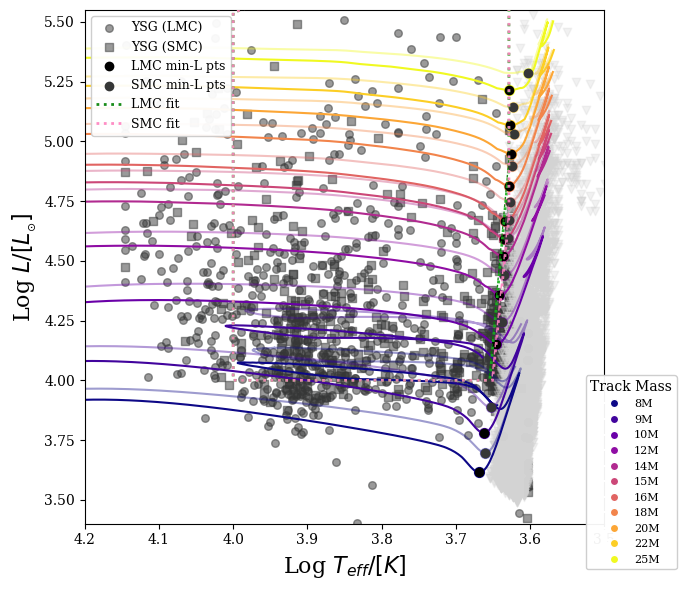

In [15]:
masses = [8, 9, 10, 12, 14, 15, 16, 18, 20, 22, 25]
color_map = cm.plasma
norm = mcolors.Normalize(vmin=0, vmax=len(masses) - 1)

def get_min_L_in_Trange_mytrack(df, logT_min=3.5, logT_max=3.7):
    """
    For a single (already-loaded) track, find the point of minimum log_L
    within a logT window. Returns (log_Teff, log_L) at that minimum,
    or (nan, nan) if the track never crosses this logT range.
    """
    log_Teff = np.asarray(df.log_Teff)
    log_L = np.asarray(df.log_L)

    mask = (log_Teff >= logT_min) & (log_Teff <= logT_max)
    if not np.any(mask):
        return np.nan, np.nan

    # index of the minimum log_L *within* the masked subset
    idx_local = np.argmin(log_L[mask])
    # map back to the index in the full array
    idx_min = np.where(mask)[0][idx_local]

    return log_Teff[idx_min], log_L[idx_min]


lmcTs = []
lmcLs = []
smcTs = []
smcLs = []

fig, ax = plt.subplots(figsize=(7, 6))

# Collect LMC data
for mass in masses:
    postMSlogdir = mr.MesaLogDir(f'../../ysg_mesa_LMC/{mass}M_alpha2.1_wind0.5/LOGS')
    h_postMS = postMSlogdir.history_data

    # only want the parts at log_Teff < 4.25 in the history table
    history_mask = h_postMS.log_Teff < 4.25
    log_Teff = h_postMS.log_Teff[history_mask]
    log_L = h_postMS.log_L[history_mask]
    ax.plot(log_Teff, log_L, color=color_map(norm(masses.index(mass))), zorder=1)

    # plot the minimum-L point in the logT range 3.5-3.7
    logT_pt, logL_pt = get_min_L_in_Trange_mytrack(h_postMS, logT_min=3.5, logT_max=3.7)
    ax.scatter(logT_pt, logL_pt, color=color_map(norm(masses.index(mass))), s=50, zorder=2)

    lmcTs.append(logT_pt)
    lmcLs.append(logL_pt)

# Collect SMC data
for mass in masses:
    postMSlogdir = mr.MesaLogDir(f'../../ysg_mesa_SMC/{mass}M_alpha2.1_wind0.5/LOGS')
    h_postMS = postMSlogdir.history_data

    # only want the parts at log_Teff < 4.25 in the history table
    history_mask = h_postMS.log_Teff < 4.25
    log_Teff = h_postMS.log_Teff[history_mask]
    log_L = h_postMS.log_L[history_mask]
    ax.plot(log_Teff, log_L, color=color_map(norm(masses.index(mass))), alpha=0.4, zorder=1)

    # plot the minimum-L point in the logT range 3.5-3.7
    logT_pt, logL_pt = get_min_L_in_Trange_mytrack(h_postMS, logT_min=3.5, logT_max=3.7)
    ax.scatter(logT_pt, logL_pt, color=color_map(norm(masses.index(mass))), s=50, alpha=0.5, zorder=2)

    smcTs.append(logT_pt)
    smcLs.append(logL_pt)


# YSGs with different colors and markers
ax.scatter(stats[stats['RA'] >= 40.0]['logT'], stats[stats['RA'] >= 40.0]['logL'], alpha=0.5, color='xkcd:dark grey', edgecolors='xkcd:dark grey', marker='o', s=30, label='YSG (LMC)', zorder=0)
ax.scatter(stats[stats['RA'] < 40.0]['logT'], stats[stats['RA'] < 40.0]['logL'], alpha=0.5, color='xkcd:dark grey', edgecolors='xkcd:dark grey', marker='s', s=30, label='YSG (SMC)', zorder=0)
    
ax.scatter(
            np.log10(rsg_lmc["Temp"]),
            rsg_lmc["LogLum"],
            alpha=0.3,
            c="lightgrey",
            zorder=0,
            marker="v",
            )

ax.scatter(
            np.log10(rsg_smc["Temp"]),
            rsg_smc["LogLum"],
            alpha=0.3,
            c="lightgrey",
            zorder=0,
            marker="v",
            )

# LMC fit line and min-L points (BLACK)
ax.scatter(lmcTs, lmcLs, color='black', label=f'LMC min-L pts', zorder=8)

linefit_LMC = np.polynomial.Polynomial.fit(lmcTs, lmcLs, 1)
intercept_lmc, slope_lmc = linefit_LMC.convert().coef
print(f"LMC: log_L = {slope_lmc:.3f} * log_Teff + {intercept_lmc:.3f}  (n={len(lmcTs)})")

# SMC fit line and min-L points (DARK GREY)
ax.scatter(smcTs, smcLs, color='xkcd:dark grey', label=f'SMC min-L pts', zorder=8)

linefit_SMC = np.polynomial.Polynomial.fit(smcTs, smcLs, 1)
intercept_smc, slope_smc = linefit_SMC.convert().coef
print(f"SMC: log_L = {slope_smc:.3f} * log_Teff + {intercept_smc:.3f}  (n={len(smcTs)})")

xarray = np.linspace(3.6, 3.7, 100)
logT_min = 3.5
logT_max = 3.7

from matplotlib.patches import Polygon

# Create LMC box patch
x0, y0 = np.log10(4250), 4.0
width, height = 4.0 - np.log10(4250), 1.6
x1, y1 = x0 + width, y0 + height

cut = 0.06
top_cutA = (x1, y1 - cut)
top_cutB = (x1 - cut, y1)

# LMC fit line chamfer
y_at_x0_lmc = slope_lmc * x0 + intercept_lmc
x_at_y0_lmc = (y0 - intercept_lmc) / slope_lmc

bottom_pts_lmc = []
if y0 <= y_at_x0_lmc <= y1:
    bottom_pts_lmc.append((x0, y_at_x0_lmc))
if x0 <= x_at_y0_lmc <= x1:
    bottom_pts_lmc.append((x_at_y0_lmc, y0))

if len(bottom_pts_lmc) >= 2:
    bottom_cutA_lmc, bottom_cutB_lmc = bottom_pts_lmc
else:
    bottom_cutA_lmc, bottom_cutB_lmc = bottom_pts_lmc[0], bottom_pts_lmc[0]

verts_lmc = [
    bottom_cutA_lmc,
    (x0, y1),
    top_cutB,
    top_cutA,
    (x1, y0),
    bottom_cutB_lmc,
]

box_patch_LMC = Polygon(
    verts_lmc,
    closed=True,
    facecolor='none',
    edgecolor='xkcd:green',
    alpha=0.9,
    zorder=20,
    linewidth=2,
    linestyle='dotted',
)
ax.add_patch(box_patch_LMC)

# Create SMC box patch
y_at_x0_smc = slope_smc * x0 + intercept_smc
x_at_y0_smc = (y0 - intercept_smc) / slope_smc

bottom_pts_smc = []
if y0 <= y_at_x0_smc <= y1:
    bottom_pts_smc.append((x0, y_at_x0_smc))
if x0 <= x_at_y0_smc <= x1:
    bottom_pts_smc.append((x_at_y0_smc, y0))

if len(bottom_pts_smc) >= 2:
    bottom_cutA_smc, bottom_cutB_smc = bottom_pts_smc
else:
    bottom_cutA_smc, bottom_cutB_smc = bottom_pts_smc[0], bottom_pts_smc[0]

verts_smc = [
    bottom_cutA_smc,
    (x0, y1),
    top_cutB,
    top_cutA,
    (x1, y0),
    bottom_cutB_smc,
]

box_patch_SMC = Polygon(
    verts_smc,
    closed=True,
    facecolor='none',
    edgecolor='xkcd:pink',
    alpha=0.9,
    zorder=20,
    linewidth=2,
    linestyle='dotted',
)
ax.add_patch(box_patch_SMC)



fit_line_LMC, = ax.plot(xarray, linefit_LMC(xarray), linestyle='dotted', linewidth=2, alpha=0.9, color='green', zorder=10, label='LMC fit')
fit_line_LMC.set_clip_path(box_patch_LMC)

fit_line_SMC, = ax.plot(xarray, linefit_SMC(xarray), linestyle='dotted', linewidth=2, alpha=0.9, color='xkcd:pink', zorder=10, label='SMC fit')
fit_line_SMC.set_clip_path(box_patch_SMC)

# Create legend for track masses positioned at bottom right, half on/half off plot
mass_handles = []
for i, mass in enumerate(masses):
    mass_handles.append(plt.Line2D([0], [0], marker='o', color='w', 
                                   markerfacecolor=color_map(norm(i)), markersize=6,
                                   label=f'{mass}M'))

# Main legend (YSG and fit lines)
main_legend = ax.legend(loc='upper left', fontsize=9, framealpha=0.95)
ax.add_artist(main_legend)

# Mass legend positioned at bottom right, partially outside plot
mass_legend = ax.legend(handles=mass_handles, loc='center right', bbox_to_anchor=(1.15, 0.1),
                        fontsize=8, title='Track Mass', framealpha=0.95)

ax.set_ylim(3.4, 5.55)
ax.set_xlim(3.5, 4.2)
ax.invert_xaxis()
ax.set_xlabel('Log $T_{eff}/[K]$', fontsize=16)
ax.set_ylabel('Log $L/[L_{_{\\odot}}]$', fontsize=16)
plt.tight_layout()
plt.savefig('./figs/hr_diagrams/Tcut_lmcsmc.png', dpi=600, bbox_inches='tight')

[np.float64(3.6683574119987954)] [np.float64(3.6147276285100594)]
[np.float64(3.6683574119987954), np.float64(3.6619464445471457)] [np.float64(3.6147276285100594), np.float64(3.77998711156336)]
[np.float64(3.6683574119987954), np.float64(3.6619464445471457), np.float64(3.645978148247345)] [np.float64(3.6147276285100594), np.float64(3.77998711156336), np.float64(4.152558715335357)]
[np.float64(3.6683574119987954), np.float64(3.6619464445471457), np.float64(3.645978148247345), np.float64(3.6411134128019182)] [np.float64(3.6147276285100594), np.float64(3.77998711156336), np.float64(4.152558715335357), np.float64(4.358792314081409)]
[np.float64(3.6683574119987954), np.float64(3.6619464445471457), np.float64(3.645978148247345), np.float64(3.6411134128019182), np.float64(3.6364343382489848)] [np.float64(3.6147276285100594), np.float64(3.77998711156336), np.float64(4.152558715335357), np.float64(4.358792314081409), np.float64(4.519241255655798)]
[np.float64(3.6683574119987954), np.float64(3.6

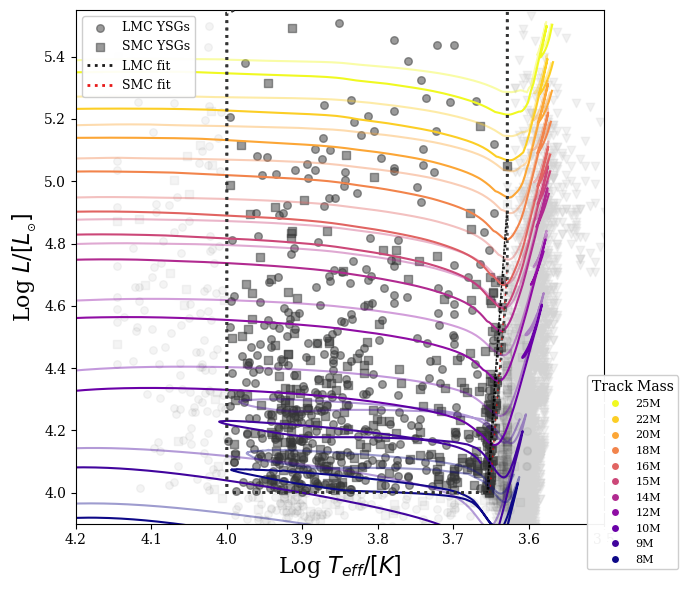

In [16]:
# Same plot but with YSGs outside the polygon having low alpha, and reversed mass legend order
from matplotlib.path import Path

masses = [8, 9, 10, 12, 14, 15, 16, 18, 20, 22, 25]
color_map = cm.plasma
norm = mcolors.Normalize(vmin=0, vmax=len(masses) - 1)

def get_min_L_in_Trange_mytrack(df, logT_min=3.5, logT_max=3.7):
    """
    For a single (already-loaded) track, find the point of minimum log_L
    within a logT window. Returns (log_Teff, log_L) at that minimum,
    or (nan, nan) if the track never crosses this logT range.
    """
    log_Teff = np.asarray(df.log_Teff)
    log_L = np.asarray(df.log_L)

    mask = (log_Teff >= logT_min) & (log_Teff <= logT_max)
    if not np.any(mask):
        return np.nan, np.nan

    # index of the minimum log_L *within* the masked subset
    idx_local = np.argmin(log_L[mask])
    # map back to the index in the full array
    idx_min = np.where(mask)[0][idx_local]

    return log_Teff[idx_min], log_L[idx_min]


def point_inside_and_correct_side(logT, logL, x0, y0, x1, y1, slope, intercept):
    """
    Check if a point is:
    1. Inside the box boundaries
    2. On the correct side of the fit line (below it, since we're fitting minimum L)
    """
    # Check box boundaries
    if not (x0 <= logT <= x1 and y0 <= logL <= y1):
        return False
    
    # Check if point is on correct side of the fit line
    # The fit line is: logL_expected = slope * logT + intercept
    # Points should be ABOVE the line (higher logL values)
    logL_on_line = slope * logT + intercept
    return logL >= logL_on_line


lmcTs = []
lmcLs = []
smcTs = []
smcLs = []

fig, ax = plt.subplots(figsize=(7, 6))

# Collect LMC data
for mass in masses:
    postMSlogdir = mr.MesaLogDir(f'../../ysg_mesa_LMC/{mass}M_alpha2.1_wind0.5/LOGS')
    h_postMS = postMSlogdir.history_data

    # only want the parts at log_Teff < 4.25 in the history table
    history_mask = h_postMS.log_Teff < 4.25
    log_Teff = h_postMS.log_Teff[history_mask]
    log_L = h_postMS.log_L[history_mask]
    ax.plot(log_Teff, log_L, color=color_map(norm(masses.index(mass))), zorder=1)

    # plot the minimum-L point in the logT range 3.5-3.7
    logT_pt, logL_pt = get_min_L_in_Trange_mytrack(h_postMS, logT_min=3.5, logT_max=3.7)
    # ax.scatter(logT_pt, logL_pt, color=color_map(norm(masses.index(mass))), s=50, zorder=2)

    lmcTs.append(logT_pt)
    lmcLs.append(logL_pt)
    print(lmcTs, lmcLs)

# Collect SMC data
for mass in masses:
    postMSlogdir = mr.MesaLogDir(f'../../ysg_mesa_SMC/{mass}M_alpha2.1_wind0.5/LOGS')
    h_postMS = postMSlogdir.history_data

    # only want the parts at log_Teff < 4.25 in the history table
    history_mask = h_postMS.log_Teff < 4.25
    log_Teff = h_postMS.log_Teff[history_mask]
    log_L = h_postMS.log_L[history_mask]
    ax.plot(log_Teff, log_L, color=color_map(norm(masses.index(mass))), alpha=0.4, zorder=1)

    # plot the minimum-L point in the logT range 3.5-3.7
    logT_pt, logL_pt = get_min_L_in_Trange_mytrack(h_postMS, logT_min=3.5, logT_max=3.7)
    # ax.scatter(logT_pt, logL_pt, color=color_map(norm(masses.index(mass))), s=50, alpha=0.5, zorder=2)

    smcTs.append(logT_pt)
    smcLs.append(logL_pt)

# LMC and SMC fit lines
linefit_LMC = np.polynomial.Polynomial.fit(lmcTs, lmcLs, 1)
intercept_lmc, slope_lmc = linefit_LMC.convert().coef
print(f"LMC: log_L = {slope_lmc:.3f} * log_Teff + {intercept_lmc:.3f}  (n={len(lmcTs)})")

linefit_SMC = np.polynomial.Polynomial.fit(smcTs, smcLs, 1)
intercept_smc, slope_smc = linefit_SMC.convert().coef
print(f"SMC: log_L = {slope_smc:.3f} * log_Teff + {intercept_smc:.3f}  (n={len(smcTs)})")

xarray = np.linspace(3.6, 3.7, 100)
logT_min = 3.5
logT_max = 3.7

from matplotlib.patches import Polygon

# Create LMC box patch
x0, y0 = np.log10(4250), 4.0
width, height = 4.0 - np.log10(4250), 1.6
x1, y1 = x0 + width, y0 + height

cut = 0.06
top_cutA = (x1, y1 - cut)
top_cutB = (x1 - cut, y1)

y_at_x0_lmc = slope_lmc * x0 + intercept_lmc
x_at_y0_lmc = (y0 - intercept_lmc) / slope_lmc

bottom_pts_lmc = []
if y0 <= y_at_x0_lmc <= y1:
    bottom_pts_lmc.append((x0, y_at_x0_lmc))
if x0 <= x_at_y0_lmc <= x1:
    bottom_pts_lmc.append((x_at_y0_lmc, y0))

if len(bottom_pts_lmc) >= 2:
    bottom_cutA_lmc, bottom_cutB_lmc = bottom_pts_lmc
else:
    bottom_cutA_lmc, bottom_cutB_lmc = bottom_pts_lmc[0], bottom_pts_lmc[0]

verts_lmc = [
    bottom_cutA_lmc,
    (x0, y1),
    top_cutB,
    top_cutA,
    (x1, y0),
    bottom_cutB_lmc,
]

box_patch_LMC = Polygon(
    verts_lmc,
    closed=True,
    facecolor='none',
    edgecolor='black',
    alpha=0.9,
    zorder=20,
    linewidth=2,
    linestyle='dotted',
)
ax.add_patch(box_patch_LMC)

# Create SMC box patch
y_at_x0_smc = slope_smc * x0 + intercept_smc
x_at_y0_smc = (y0 - intercept_smc) / slope_smc

bottom_pts_smc = []
if y0 <= y_at_x0_smc <= y1:
    bottom_pts_smc.append((x0, y_at_x0_smc))
if x0 <= x_at_y0_smc <= x1:
    bottom_pts_smc.append((x_at_y0_smc, y0))

if len(bottom_pts_smc) >= 2:
    bottom_cutA_smc, bottom_cutB_smc = bottom_pts_smc
else:
    bottom_cutA_smc, bottom_cutB_smc = bottom_pts_smc[0], bottom_pts_smc[0]

verts_smc = [
    bottom_cutA_smc,
    (x0, y1),
    top_cutB,
    top_cutA,
    (x1, y0),
    bottom_cutB_smc,
]

box_patch_SMC = Polygon(
    verts_smc,
    closed=True,
    facecolor='none',
    edgecolor='xkcd:dark grey',
    alpha=0.9,
    zorder=20,
    linewidth=2,
    linestyle='dotted',
)
ax.add_patch(box_patch_SMC)

# Separate YSGs by whether they're inside the valid region
lmc_ysg = stats[stats['RA'] >= 40.0]
smc_ysg = stats[stats['RA'] < 40.0]

# Check LMC YSGs
lmc_inside = np.array([point_inside_and_correct_side(row['logT'], row['logL'], x0, y0, x1, y1, slope_lmc, intercept_lmc) 
                       for _, row in lmc_ysg.iterrows()]) if len(lmc_ysg) > 0 else np.array([])
lmc_outside = ~lmc_inside if len(lmc_inside) > 0 else np.array([])

# Check SMC YSGs
smc_inside = np.array([point_inside_and_correct_side(row['logT'], row['logL'], x0, y0, x1, y1, slope_smc, intercept_smc) 
                       for _, row in smc_ysg.iterrows()]) if len(smc_ysg) > 0 else np.array([])
smc_outside = ~smc_inside if len(smc_inside) > 0 else np.array([])

# Plot LMC YSGs
if len(lmc_ysg) > 0:
    if lmc_inside.any():
        ax.scatter(lmc_ysg[lmc_inside]['logT'], lmc_ysg[lmc_inside]['logL'], 
                  alpha=0.5, color='xkcd:dark grey', edgecolors='xkcd:dark grey', marker='o', s=30, label='LMC YSGs', zorder=0)
    if lmc_outside.any():
        ax.scatter(lmc_ysg[lmc_outside]['logT'], lmc_ysg[lmc_outside]['logL'], 
                  alpha=0.05, color='xkcd:dark grey', edgecolors='xkcd:dark grey', marker='o', s=30, zorder=0)

# Plot SMC YSGs
if len(smc_ysg) > 0:
    if smc_inside.any():
        ax.scatter(smc_ysg[smc_inside]['logT'], smc_ysg[smc_inside]['logL'], 
                  alpha=0.5, color='xkcd:dark grey', edgecolors='xkcd:dark grey', marker='s', s=30, label='SMC YSGs', zorder=0)
    if smc_outside.any():
        ax.scatter(smc_ysg[smc_outside]['logT'], smc_ysg[smc_outside]['logL'], 
                  alpha=0.05, color='xkcd:dark grey', edgecolors='xkcd:dark grey', marker='s', s=30, zorder=0)

ax.scatter(
            np.log10(rsg_lmc["Temp"]),
            rsg_lmc["LogLum"],
            alpha=0.3,
            c="lightgrey",
            zorder=-6,
            marker="v",
            )

ax.scatter(
            np.log10(rsg_smc["Temp"]),
            rsg_smc["LogLum"],
            alpha=0.3,
            c="lightgrey",
            zorder=-6,
            marker="v",
            )

# LMC fit line and min-L points (BLACK)
# ax.scatter(lmcTs, lmcLs, color='black', label=f'LMC min-L pts', zorder=8)

# SMC fit line and min-L points (DARK GREY)
# ax.scatter(smcTs, smcLs, color='xkcd:dark grey', label=f'SMC min-L pts', zorder=8)

# Plot fit lines with correct clipping
fit_line_LMC, = ax.plot(xarray, linefit_LMC(xarray), linestyle='dotted', linewidth=2, alpha=0.9, color='black', zorder=10, label='LMC fit')
fit_line_LMC.set_clip_path(box_patch_LMC)

fit_line_SMC, = ax.plot(xarray, linefit_SMC(xarray), linestyle='dotted', linewidth=2, alpha=0.9, color='xkcd:red', zorder=10, label='SMC fit')
fit_line_SMC.set_clip_path(box_patch_SMC)

# Create legend for track masses with REVERSED order
mass_handles = []
for i, mass in enumerate(reversed(masses)):
    # Get the index in the original masses list
    orig_idx = masses.index(mass)
    mass_handles.append(plt.Line2D([0], [0], marker='o', color='w', 
                                   markerfacecolor=color_map(norm(orig_idx)), markersize=6,
                                   label=f'{mass}M'))

# Main legend (YSG and fit lines)
main_legend = ax.legend(loc='upper left', fontsize=9, framealpha=0.95)
ax.add_artist(main_legend)

# Mass legend positioned at bottom right, partially outside plot, with reversed order
mass_legend = ax.legend(handles=mass_handles, loc='center right', bbox_to_anchor=(1.15, 0.1),
                        fontsize=8, title='Track Mass', framealpha=0.95)

ax.set_ylim(3.9, 5.55)
ax.set_xlim(3.5, 4.2)
ax.invert_xaxis()
ax.set_xlabel('Log $T_{eff}/[K]$', fontsize=16)
ax.set_ylabel('Log $L/[L_{_{\\odot}}]$', fontsize=16)
plt.tight_layout()
plt.savefig('./figs/hr_diagrams/plot_SMC_LMC_minL_fit_mytracks_alphaMask.png', dpi=600, bbox_inches='tight')

Min-L fit: log_L = -12.201 * log_Teff + 48.629  (n=6)


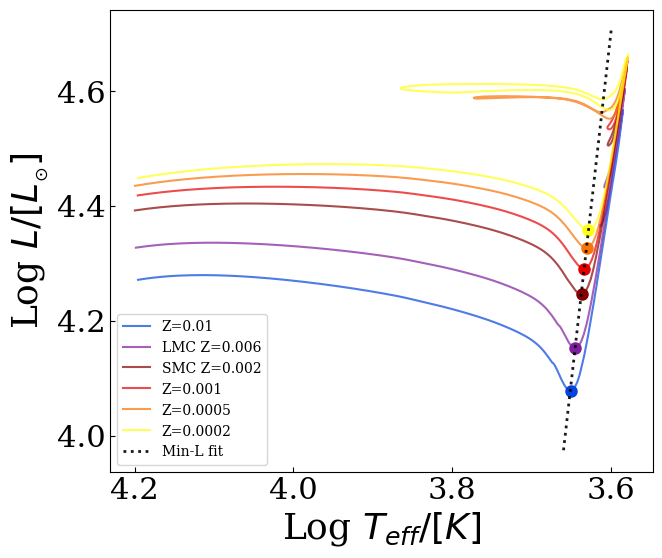

In [46]:
fig, ax = plt.subplots(figsize=(7, 6))

min_Ls = []
min_Ts = []

postMSlogdir = mr.MesaLogDir(f'../../ysg_mesa_varyZ/10M_alpha2.1_wind0.5_Z0.01/LOGS')
h_postMS = postMSlogdir.history_data

# only want the parts at log_Teff < 4.25 in the history table
history_mask = h_postMS.log_Teff < 4.2
log_Teff = h_postMS.log_Teff[history_mask]
log_L = h_postMS.log_L[history_mask]
metallicity_color = {'0.01': 'xkcd:blue', '0.001': 'xkcd:red', '0.0005': 'xkcd:orange', '0.0002': 'xkcd:yellow'}
ax.plot(log_Teff, log_L, color=metallicity_color['0.01'], alpha = 0.7, zorder=1, label=f'Z=0.01')
# min-L points
logT_pt, logL_pt = get_min_L_in_Trange_mytrack(h_postMS, logT_min=3.5, logT_max=3.7)
min_Ls.append(logL_pt)
min_Ts.append(logT_pt)
ax.plot(logT_pt, logL_pt, marker='o', color=metallicity_color['0.01'], markersize=8, zorder=2)

postMSlogdir = mr.MesaLogDir(f'../../ysg_mesa_LMC/10M_alpha2.1_wind0.5/LOGS')
h_postMS = postMSlogdir.history_data
# only want the parts at log_Teff < 4.25 in the history table
history_mask = h_postMS.log_Teff < 4.2
log_Teff = h_postMS.log_Teff[history_mask]
log_L = h_postMS.log_L[history_mask]
ax.plot(log_Teff, log_L, color='xkcd:purple', alpha = 0.7, zorder=1, label=f'LMC Z=0.006')
# min-L points
logT_pt, logL_pt = get_min_L_in_Trange_mytrack(h_postMS, logT_min=3.5, logT_max=3.7)
min_Ls.append(logL_pt)
min_Ts.append(logT_pt)
ax.plot(logT_pt, logL_pt, marker='o', color='xkcd:purple', markersize=8, zorder=2)

postMSlogdir = mr.MesaLogDir(f'../../ysg_mesa_SMC/10M_alpha2.1_wind0.5/LOGS')
h_postMS = postMSlogdir.history_data
# only want the parts at log_Teff < 4.25 in the history table
history_mask = h_postMS.log_Teff < 4.2
log_Teff = h_postMS.log_Teff[history_mask]
log_L = h_postMS.log_L[history_mask]
ax.plot(log_Teff, log_L, color='xkcd:dark red', alpha = 0.7, zorder=1, label=f'SMC Z=0.002')
# min-L points
logT_pt, logL_pt = get_min_L_in_Trange_mytrack(h_postMS, logT_min=3.5, logT_max=3.7)
min_Ls.append(logL_pt)
min_Ts.append(logT_pt)
ax.plot(logT_pt, logL_pt, marker='o', color='xkcd:dark red', markersize=8, zorder=2)


for metallicity in ['0.001', '0.0005', '0.0002']:
    postMSlogdir = mr.MesaLogDir(f'../../ysg_mesa_varyZ/10M_alpha2.1_wind0.5_Z{metallicity}/LOGS')
    h_postMS = postMSlogdir.history_data

    # only want the parts at log_Teff < 4.25 in the history table
    history_mask = h_postMS.log_Teff < 4.2
    log_Teff = h_postMS.log_Teff[history_mask]
    log_L = h_postMS.log_L[history_mask]
    metallicity_color = {'0.01': 'xkcd:blue', '0.001': 'xkcd:red', '0.0005': 'xkcd:orange', '0.0002': 'xkcd:yellow'}
    ax.plot(log_Teff, log_L, color=metallicity_color[metallicity], alpha = 0.7, zorder=1, label=f'Z={metallicity}')
    # min-L points
    logT_pt, logL_pt = get_min_L_in_Trange_mytrack(h_postMS, logT_min=3.5, logT_max=3.7)
    min_Ls.append(logL_pt)
    min_Ts.append(logT_pt)
    ax.plot(logT_pt, logL_pt, marker='o', color=metallicity_color[metallicity], markersize=8, zorder=2)


# fit a line thru minimum L
linefit_minL = np.polynomial.Polynomial.fit(min_Ts, min_Ls, 1)
intercept_minL, slope_minL = linefit_minL.convert().coef
print(f"Min-L fit: log_L = {slope_minL:.3f} * log_Teff + {intercept_minL:.3f}  (n={len(min_Ts)})")
xarray = np.linspace(3.6, 3.66, 100)
ax.plot(xarray, linefit_minL(xarray), linestyle='dotted', linewidth=2, alpha=0.9, color='black', zorder=10, label='Min-L fit')



ax.invert_xaxis()
# ax.set_xlim(4.33, 3.55)
# ax.set_ylim(3.42, 5.55)
ax.set_xlabel('Log $T_{eff}/[K]$', fontsize=26)
ax.set_ylabel('Log $L/[L_{_{\\odot}}]$', fontsize=26)
ax.tick_params(axis="both", direction="in", labelsize=22)
ax.legend()
plt.savefig('./figs/hr_diagrams/plot_minL_fit_varyZ.png', dpi=600, bbox_inches='tight')
plt.show()

In [17]:
###### SMC

# T cut
Tmaskbox = (df_smc["logT"] > 3.6) & (df_smc["logT"] < 4.0)
Lmaskbox = (df_smc["logL"] > 4.0)
smcboxcut = Tmaskbox & Lmaskbox
print(f"Number of SMC stars in box: {smcboxcut.sum()}")
#SMC: log_L = -30.885 * log_Teff + 116.746
linefit_mask_smc = df_smc["logL"] > (-30.885 * df_smc["logT"] + 116.746)
print(f"Number of SMC stars above line: {linefit_mask_smc.sum()}")
finalmask_smc = smcboxcut & linefit_mask_smc
print(f"Number of SMC stars in box and above line: {finalmask_smc.sum()}")

Tmaskbox = (df_lmc["logT"] > 3.6) & (df_lmc["logT"] < 4.0)
Lmaskbox = (df_lmc["logL"] > 4.0)
lmcboxcut = Tmaskbox & Lmaskbox
print(f"Number of LMC stars in box: {lmcboxcut.sum()}")
#LMC: log_L = -34.596 * log_Teff + 130.425
#cut based on line
linefit_mask_lmc = df_lmc["logL"] > (-34.596 * df_lmc["logT"] + 130.425)
print(f"Number of LMC stars above line: {linefit_mask_lmc.sum()}")
finalmask_lmc = lmcboxcut & linefit_mask_lmc
print(f"Number of LMC stars above line and in box: {finalmask_lmc.sum()}")

# total stars new T, L cut:
print(f"Total number of stars in box and above line: {finalmask_smc.sum() + finalmask_lmc.sum()}")
# make it a new df
df_new = pd.concat([df_smc[finalmask_smc], df_lmc[finalmask_lmc]])

# bad lightcurves, cut our where overall_mean is nan
df_newT = df_new[df_new["overall_mean"].notna()]
print(f"Total number of stars in box and above line after cutting bad lightcurves: {len(df_newT)}")

Number of SMC stars in box: 448
Number of SMC stars above line: 353
Number of SMC stars in box and above line: 294
Number of LMC stars in box: 441
Number of LMC stars above line: 651
Number of LMC stars above line and in box: 404
Total number of stars in box and above line: 698
Total number of stars in box and above line after cutting bad lightcurves: 642


In [40]:
# make new csv of df_new
# sort by index
df_newT = df_newT.sort_values(by='star_idx')

df_newT.to_csv("./ysg_candidates_Tcut_08272026.csv", index=False)

In [41]:
# Problem stars:
T_to_check = [51, 106, 111, 119, 200, 204, 213, 294, 307, 322, 347, 398, 399, 429, 442, 496, 504, 514, 563, 579, 609, 618, 714, 733, 742, 749, 753, 757, 775, 777, 780, 854, 857, 866, 873, 896, 897, 931, 947, 965, 967, 1025, 1034, 1047, 1067, 1083, 1085, 1103, 1111, 1116, 1117, 1123, 1124, 1135, 1152, 1160, 1161, 1178, 1182, 1238, 1239, 1269]
print(len(T_to_check))

62


In [42]:
# stars that are contaminants:
contaminants = [395, 444, 495, 790, 829, 839, 843, 1068, 44, 54, 65, 66, 68, 77, 79, 91, 143, 153, 163, 218, 225, 260, 872, 902, 907, 516, 839, 181, 193]
# see how many are in df_new
print(f"Number of contaminants in df_new: {df_newT[df_newT['star_idx'].isin(contaminants)].shape[0]}")
print(f"Number of contaminants in df_new: {df_newT[df_newT['star_idx'].isin(contaminants)]}")

Number of contaminants in df_new: 13
Number of contaminants in df_new:      star_idx         RA        DEC  overall_mean  overall_median  \
65         65  12.419711 -73.236916      5.884078        5.697450   
68         68  12.482258 -73.047455      9.169933        9.150138   
193       193  13.794910 -72.452660     28.385305       28.388690   
218       218  14.087205 -72.845520     11.345893       11.341000   
225       225  14.127534 -72.231476      4.620118        4.603000   
395       395  72.485769 -69.755859     42.251135       41.408000   
444       444  74.058839 -67.413483     28.438405       28.406449   
495       495  75.158007 -67.764633     21.126018       21.116369   
790       790  85.465791 -70.423386     19.660146       19.654281   
829       829  86.675929 -68.008675      8.130067        8.121000   
839       839  88.223970 -69.487930     37.496146       37.494036   
902       902  14.603494 -72.422890      6.462113        6.459941   
907       907  13.615561 -72.266

In [43]:
df_new_nocontaminants = df_newT[~df_newT['star_idx'].isin(contaminants)]
print(f"Number of stars in df_new after removing contaminants: {len(df_new_nocontaminants)}")

Number of stars in df_new after removing contaminants: 629


In [44]:
# make new csv of df_new_nocontaminants
df_new_nocontaminants = df_new_nocontaminants.sort_values(by='star_idx')
df_new_nocontaminants.to_csv("./ysg_candidates_Tcut_nocontaminants_08272026.csv", index=False)

In [45]:
# how many are statistically variable

df_new_nocontaminants_var = df_new_nocontaminants[df_new_nocontaminants['alarm_level_flag'] == 0]
print(f"Number of stars in df_new_nocontaminants that are statistically variable: {len(df_new_nocontaminants_var)}")

Number of stars in df_new_nocontaminants that are statistically variable: 533


In [46]:
# define luminosity zones
Lzone1 = (df_new_nocontaminants["logL"] >= 4.0) & (df_new_nocontaminants["logL"] < 4.2)
Lzone2 = (df_new_nocontaminants["logL"] >= 4.2) & (df_new_nocontaminants["logL"] < 4.4)
Lzone3 = (df_new_nocontaminants["logL"] >= 4.4) & (df_new_nocontaminants["logL"] < 4.6)
Lzone4 = (df_new_nocontaminants["logL"] >= 4.6) & (df_new_nocontaminants["logL"] < 4.8)
# Lzone5 = (df_new_nocontaminants["logL"] >= 4.8) & (df_new_nocontaminants["logL"] < 5.0)
# Lzone6 = (df_new_nocontaminants["logL"] >= 5.0) & (df_new_nocontaminants["logL"] < 5.2)
Lzone5 = (df_new_nocontaminants["logL"] >= 4.8)

# compute the fraction of stars in each zone that are statistically variable
for i, Lzone in enumerate([Lzone1, Lzone2, Lzone3, Lzone4, Lzone5]):
    num_stars = Lzone.sum()
    num_var_stars = df_new_nocontaminants[Lzone & (df_new_nocontaminants['alarm_level_flag'] == 0)].shape[0]
    frac_var = num_var_stars / num_stars if num_stars > 0 else 0
    print(f"Luminosity zone {i+1}: {num_var_stars}/{num_stars} stars are statistically variable ({frac_var:.2%})")


Luminosity zone 1: 228/283 stars are statistically variable (80.57%)
Luminosity zone 2: 140/170 stars are statistically variable (82.35%)
Luminosity zone 3: 79/84 stars are statistically variable (94.05%)
Luminosity zone 4: 51/54 stars are statistically variable (94.44%)
Luminosity zone 5: 35/38 stars are statistically variable (92.11%)


Luminosity zone 1: 133/154 stars are statistically variable (86.36%)
Luminosity zone 2: 79/87 stars are statistically variable (90.80%)
Luminosity zone 3: 52/52 stars are statistically variable (100.00%)
Luminosity zone 4: 30/30 stars are statistically variable (100.00%)
Luminosity zone 5: 24/24 stars are statistically variable (100.00%)
Luminosity zone 1: 95/129 stars are statistically variable (73.64%)
Luminosity zone 2: 61/83 stars are statistically variable (73.49%)
Luminosity zone 3: 27/32 stars are statistically variable (84.38%)
Luminosity zone 4: 21/24 stars are statistically variable (87.50%)
Luminosity zone 5: 11/14 stars are statistically variable (78.57%)


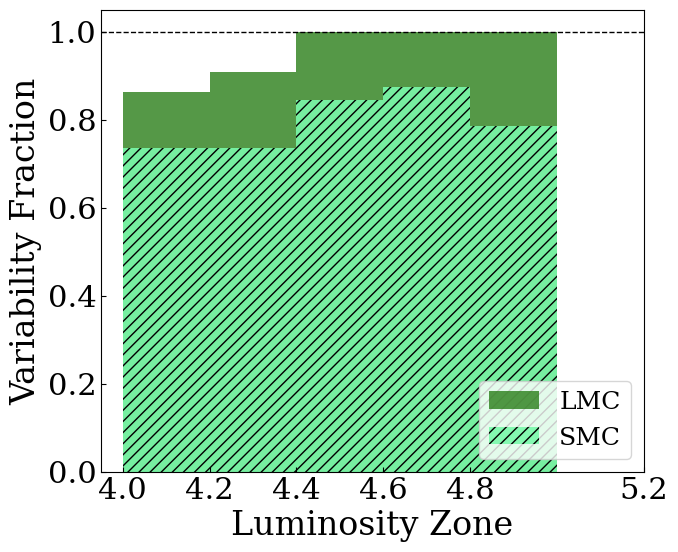

In [47]:
# define luminosity zones for LMC only
df_new_nocontaminants_lmc = df_new_nocontaminants[df_new_nocontaminants['RA'] >= 40.0]
Lzone1_LMC = (df_new_nocontaminants_lmc["logL"] >= 4.0) & (df_new_nocontaminants_lmc["logL"] < 4.2)
Lzone2_LMC = (df_new_nocontaminants_lmc["logL"] >= 4.2) & (df_new_nocontaminants_lmc["logL"] < 4.4)
Lzone3_LMC = (df_new_nocontaminants_lmc["logL"] >= 4.4) & (df_new_nocontaminants_lmc["logL"] < 4.6)
Lzone4_LMC = (df_new_nocontaminants_lmc["logL"] >= 4.6) & (df_new_nocontaminants_lmc["logL"] < 4.8)
# Lzone5 = (df_new_nocontaminants["logL"] >= 4.8) & (df_new_nocontaminants["logL"] < 5.0)
# Lzone6 = (df_new_nocontaminants["logL"] >= 5.0) & (df_new_nocontaminants["logL"] < 5.2)
Lzone5_LMC = (df_new_nocontaminants_lmc["logL"] >= 4.8)

# compute the fraction of stars in each zone that are statistically variable
for i, Lzone in enumerate([Lzone1_LMC, Lzone2_LMC, Lzone3_LMC, Lzone4_LMC, Lzone5_LMC]):
    num_stars = Lzone.sum()
    num_var_stars = df_new_nocontaminants_lmc[Lzone & (df_new_nocontaminants_lmc['alarm_level_flag'] == 0)].shape[0]
    frac_var = num_var_stars / num_stars if num_stars > 0 else 0
    print(f"Luminosity zone {i+1}: {num_var_stars}/{num_stars} stars are statistically variable ({frac_var:.2%})")

df_new_nocontaminants_smc = df_new_nocontaminants[df_new_nocontaminants['RA'] < 40.0]
Lzone1_SMC = (df_new_nocontaminants_smc["logL"] >= 4.0) & (df_new_nocontaminants_smc["logL"] < 4.2)
Lzone2_SMC = (df_new_nocontaminants_smc["logL"] >= 4.2) & (df_new_nocontaminants_smc["logL"] < 4.4)
Lzone3_SMC = (df_new_nocontaminants_smc["logL"] >= 4.4) & (df_new_nocontaminants_smc["logL"] < 4.6)
Lzone4_SMC = (df_new_nocontaminants_smc["logL"] >= 4.6) & (df_new_nocontaminants_smc["logL"] < 4.8)
# Lzone5 = (df_new_nocontaminants["logL"] >= 4.8) & (df_new_nocontaminants["logL"] < 5.0)
# Lzone6 = (df_new_nocontaminants["logL"] >= 5.0) & (df_new_nocontaminants["logL"] < 5.2)
Lzone5_SMC = (df_new_nocontaminants_smc["logL"] >= 4.8)
# Lzone6_SMC = (df_new_nocontaminants_smc["logL"] >= 5.0) & (df_new_nocontaminants_smc["logL"] < 5.2)

# compute the fraction of stars in each zone that are statistically variable
for i, Lzone in enumerate([Lzone1_SMC, Lzone2_SMC, Lzone3_SMC, Lzone4_SMC, Lzone5_SMC]):
    num_stars = Lzone.sum()
    num_var_stars = df_new_nocontaminants_smc[Lzone & (df_new_nocontaminants_smc['alarm_level_flag'] == 0)].shape[0]
    frac_var = num_var_stars / num_stars if num_stars > 0 else 0
    print(f"Luminosity zone {i+1}: {num_var_stars}/{num_stars} stars are statistically variable ({frac_var:.2%})")

# create histogram of variability fraction in each luminosity zone for LMC and SMC
fig, ax = plt.subplots(figsize=(7, 6))

# Plot the variability fractions for LMC
lmc_var_fractions = [
    df_new_nocontaminants_lmc[Lzone1_LMC & (df_new_nocontaminants_lmc['alarm_level_flag'] == 0)].shape[0] / Lzone1_LMC.sum(),
    df_new_nocontaminants_lmc[Lzone2_LMC & (df_new_nocontaminants_lmc['alarm_level_flag'] == 0)].shape[0] / Lzone2_LMC.sum(),
    df_new_nocontaminants_lmc[Lzone3_LMC & (df_new_nocontaminants_lmc['alarm_level_flag'] == 0)].shape[0] / Lzone3_LMC.sum(),
    df_new_nocontaminants_lmc[Lzone4_LMC & (df_new_nocontaminants_lmc['alarm_level_flag'] == 0)].shape[0] / Lzone4_LMC.sum(),
    df_new_nocontaminants_lmc[Lzone5_LMC & (df_new_nocontaminants_lmc['alarm_level_flag'] == 0)].shape[0] / Lzone5_LMC.sum()
]
smc_var_fractions = [
    df_new_nocontaminants_smc[Lzone1_SMC & (df_new_nocontaminants_smc['alarm_level_flag'] == 0)].shape[0] / Lzone1_SMC.sum(),
    df_new_nocontaminants_smc[Lzone2_SMC & (df_new_nocontaminants_smc['alarm_level_flag'] == 0)].shape[0] / Lzone2_SMC.sum(),
    df_new_nocontaminants_smc[Lzone3_SMC & (df_new_nocontaminants_smc['alarm_level_flag'] == 0)].shape[0] / Lzone3_SMC.sum(),
    df_new_nocontaminants_smc[Lzone4_SMC & (df_new_nocontaminants_smc['alarm_level_flag'] == 0)].shape[0] / Lzone4_SMC.sum(),
    df_new_nocontaminants_smc[Lzone5_SMC & (df_new_nocontaminants_smc['alarm_level_flag'] == 0)].shape[0] / Lzone5_SMC.sum()
]

#how to make box lines
# ax.spines['top'].set_visible(True)
# ax.spines['right'].set_visible(False)
ax.bar([4.1, 4.3, 4.5, 4.7, 4.9], lmc_var_fractions, width=0.2, label='LMC', color='xkcd:tree green',  alpha=0.8)
ax.bar([4.1, 4.3, 4.5, 4.7, 4.9], smc_var_fractions, width=0.2, label='SMC', color='xkcd:seafoam green', hatch='///',alpha=0.9)
# horizontal line at 1.0
ax.axhline(y=1.0, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Luminosity Zone', fontsize=24)
ax.set_ylabel('Variability Fraction', fontsize=24)
ax.tick_params(axis="both", direction="in", labelsize=22)
ax.set_xticks([4.0, 4.2, 4.4, 4.6, 4.8, 5.2])
ax.legend(loc='lower right', fontsize=18, facecolor="white")
plt.savefig('./figs/hr_diagrams/ysg_candidates_variabilityfraction.png', dpi=600, bbox_inches='tight')


In [48]:
Tzone1 = (df_new_nocontaminants["logT"] >= 3.6) & (df_new_nocontaminants["logT"] < 3.7)
Tzone2 = (df_new_nocontaminants["logT"] >= 3.7) & (df_new_nocontaminants["logT"] < 3.8)
Tzone3 = (df_new_nocontaminants["logT"] >= 3.8) & (df_new_nocontaminants["logT"] < 3.9)
Tzone4 = (df_new_nocontaminants["logT"] >= 3.9) & (df_new_nocontaminants["logT"] < 4.0)

# compute the fraction of stars in each zone that are statistically variable
for i, Tzone in enumerate([Tzone1, Tzone2, Tzone3, Tzone4]):
    num_stars = Tzone.sum()
    num_var_stars = df_new_nocontaminants[Tzone & (df_new_nocontaminants['alarm_level_flag'] == 0)].shape[0]
    frac_var = num_var_stars / num_stars if num_stars > 0 else 0
    print(f"Temperature zone {i+1}: {num_var_stars}/{num_stars} stars are statistically variable ({frac_var:.2%})")

Temperature zone 1: 138/153 stars are statistically variable (90.20%)
Temperature zone 2: 91/103 stars are statistically variable (88.35%)
Temperature zone 3: 134/172 stars are statistically variable (77.91%)
Temperature zone 4: 170/201 stars are statistically variable (84.58%)


In [49]:
# check what proposed are still in df_new_nocontaminants
proposed = [307,1130,613,1085,716,953,250,890,156,40,780,522]
for star in proposed:
    if star in df_new_nocontaminants['star_idx'].values:
        print(f"Star {star} is still in df_new_nocontaminants")
    else:
        print(f"Star {star} is NOT in df_new_nocontaminants")

Star 307 is still in df_new_nocontaminants
Star 1130 is still in df_new_nocontaminants
Star 613 is still in df_new_nocontaminants
Star 1085 is still in df_new_nocontaminants
Star 716 is still in df_new_nocontaminants
Star 953 is still in df_new_nocontaminants
Star 250 is still in df_new_nocontaminants
Star 890 is still in df_new_nocontaminants
Star 156 is still in df_new_nocontaminants
Star 40 is still in df_new_nocontaminants
Star 780 is still in df_new_nocontaminants
Star 522 is still in df_new_nocontaminants


# make the copy for the new lcs

In [18]:
stats = pd.read_csv('./summary_results09152026.csv')
df_smc = stats[stats['RA'] < 40]
df_lmc = stats[stats['RA'] > 40]

In [19]:
###### SMC

# T cut
Tmaskbox = (df_smc["logT"] > 3.6) & (df_smc["logT"] < 4.0)
Lmaskbox = (df_smc["logL"] > 4.0)
smcboxcut = Tmaskbox & Lmaskbox
print(f"Number of SMC stars in box: {smcboxcut.sum()}")
#SMC: log_L = -30.885 * log_Teff + 116.746
linefit_mask_smc = df_smc["logL"] > (-30.885 * df_smc["logT"] + 116.746)
print(f"Number of SMC stars above line: {linefit_mask_smc.sum()}")
finalmask_smc = smcboxcut & linefit_mask_smc
print(f"Number of SMC stars in box and above line: {finalmask_smc.sum()}")

Tmaskbox = (df_lmc["logT"] > 3.6) & (df_lmc["logT"] < 4.0)
Lmaskbox = (df_lmc["logL"] > 4.0)
lmcboxcut = Tmaskbox & Lmaskbox
print(f"Number of LMC stars in box: {lmcboxcut.sum()}")
#LMC: log_L = -34.596 * log_Teff + 130.425
#cut based on line
linefit_mask_lmc = df_lmc["logL"] > (-34.596 * df_lmc["logT"] + 130.425)
print(f"Number of LMC stars above line: {linefit_mask_lmc.sum()}")
finalmask_lmc = lmcboxcut & linefit_mask_lmc
print(f"Number of LMC stars above line and in box: {finalmask_lmc.sum()}")

# total stars new T, L cut:
print(f"Total number of stars in box and above line: {finalmask_smc.sum() + finalmask_lmc.sum()}")
# make it a new df
df_new = pd.concat([df_smc[finalmask_smc], df_lmc[finalmask_lmc]])

# bad lightcurves, cut our where overall_mean is nan
df_newT = df_new[df_new["overall_mean"].notna()]
print(f"Total number of stars in box and above line after cutting bad lightcurves: {len(df_newT)}")

Number of SMC stars in box: 448
Number of SMC stars above line: 353
Number of SMC stars in box and above line: 294
Number of LMC stars in box: 441
Number of LMC stars above line: 651
Number of LMC stars above line and in box: 404
Total number of stars in box and above line: 698
Total number of stars in box and above line after cutting bad lightcurves: 698
